# 1. Définir l'agent

Nous voulons faire un **agent conversationnel spécialisé** dans le cas d'usage suivant : un assistant documentaire (qui s'appuiera donc sur un RAG) sur de la documentation industrielle.

- **Utilisateur cible :** un technicien
- **Demandes qu'il doit traiter :** toute question portant sur la documentation fournie
- **Demandes qu'il doit refuser :** des questions générales qui n'ont pas de rapport avec la documentation qui lui est fournie. (Exemple : "Quel temps fait-il à Paris ?", "Quelle est la capitale de la France ?"). Cela peut être également des questions *proches* de la documentation mais dont la réponse exacte n'est pas contenue dans les extraits que l'agent reçoit. Il ne doit pas inventer, mais se contenter de signaler que l'information est absente de sa documentation.
- La documentation est basée sur un **corpus de manuels Siemens** (SIMATIC S7-1200/S7-1500 et SINAMICS G120, 13 documents, FR + EN), donc le découpage en extraits a préparé en amont.

Exemples de conversation:

**Question :** "J'ai A50020 \"Second controller missing\" sur mon variateur en PROFINET."

**Réponse :** "La fonction Shared Device est activée (p8929 = 2) mais une seule connexion à un contrôleur PROFINET est présente [Source 1]. Vérifiez la configuration des contrôleurs PROFINET et le réglage de p8929 [Source 1].

**Question :** "Comment savoir si le mode économie d'énergie PROFIenergy est actif ?"

**Réponse :** "Avec r5613 : le bit 0 vaut 1 quand PROFIenergy est actif, le bit 1 quand il est inactif ; les deux bits sont inverses l'un de l'autre [Source 1]."

**Question :** "Combien de sauvegardes de paramètres peut-on mettre sur la carte mémoire ?"

**Réponse :** "Jusqu'à 99 réglages différents [Source 1]."

**Question :** "Who won the last FIFA World Cup?"

**Réponse :** "Information absente de la documentation fournie."

**Question :** "Que faire face à l'alarme A01900 en PROFIBUS ?" (cette question est trompeuse car la signification de l'alarme A01900 est documentée mais il n'est pas dit de marche à suivre quant à sa résolution)

**Réponse :** "Information absente de la documentation fournie."

# Setup et chargement du modèle

- Modèle choisi : Qwen 2.5 7B Instruct (multilingue, reporté plutôt bon pour des tâches variées d'agent conversationnel)
- On le charge avec une quantization 4 bits pour diviser par 4 l'empreinte mémoire et le faire tenir dans 5-6Go de VRAM au lieu de ~15Go.

In [ ]:
!pip install bitsandbytes

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
import torch

# Charger la config de quantization 4 bits
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4", # format NormalFloat4
    bnb_4bit_compute_dtype=torch.float16, # les poids sont stockés en 4 bits, mais déquantifiés à la volée en float16 pour les calculs
    bnb_4bit_use_double_quant=True, # quantifie aussi les constantes de quantification, ce qui économise encore un peu de mémoire
)

model_id = "Qwen/Qwen2.5-3B-Instruct"

# Télécharge le tokenizer correspondant au modèle
tokenizer = AutoTokenizer.from_pretrained(model_id)

# Chargement optimisé avec quantization (requiert bitsandbytes)
# Télécharge les poids et instancie le bon modèle
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype="auto",
    device_map="auto", # répartit les couches sur GPU (et CPU si besoin)
    quantization_config=quantization_config # quantization pour diviser par 4 l'empreinte mémoire (~5-6 Go de VRAM au lieu des ~15Go nécessaires)
)


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

# 2. Observer le modèle

## Observer la tokenisation et la distribution de sortie du modèle

In [ ]:
import torch.nn.functional as F

prompt = "Le chat chasse la"

############ Observer les identifiants de la tokenisation ##########################

print("-- Tokenization : --")
inputs = tokenizer(prompt, return_tensors="pt") # renvoie dictionnaire de tensors PyTorch
# inputs contient input_ids, attention_mask de forme [1, n_tokens]

# Mettre chaque tenseur sur le même périphérique que le modèle (GPU en l'occurrence)
inputs = {k: v.to(model.device) for k, v in inputs.items()}

# Observer les identifiants des tokens
input_ids = inputs["input_ids"][0] # [0] pour retirer la dimension de batch (on n'a qu'une séquence)
print(f"Texte input : {prompt}")
print(f"Identifiants input_ids : {input_ids}")

# Afficher chaque id avec son token décodé
for idx in input_ids:
  print(f"ID {idx:5d} = Token : {tokenizer.decode(idx)}")

############ Observer les logits ##########################

print(f"\n\n-- Logits --")

# Passage de la séquence tokenisée au modèle
with torch.no_grad(): # désactive le calcul des gradients pour l'inférence (inutile, économie de mémoire)
    outputs = model(**inputs) # forward pass en dépaquetant le dictionnaire en args nommés

# Les logits de sortie ont la forme : [batch_size, sequence_length, vocab_size]
# Nous voulons uniquement les logits du dernier token pour prédire la suite de la séquence
next_token_logits = outputs.logits[0, -1, :] # prendre le batch 0, dernière position, et tout le vocab

print(f"Shape du tenseur de logits complet : {outputs.logits.shape}")
print(f"Shape des logits pour le prochain token : {next_token_logits.shape}")
print(f"Le modèle a généré un score brut pour chacun des {next_token_logits.shape[0]} tokens de son vocabulaire.")

-- Tokenization : --
Texte input : Le chat chasse la
Identifiants input_ids : tensor([ 2304,  6236,   521, 13256,  1187], device='cuda:0')
ID  2304 = Token : Le
ID  6236 = Token :  chat
ID   521 = Token :  ch
ID 13256 = Token : asse
ID  1187 = Token :  la


-- Logits --
Shape du tenseur de logits complet : torch.Size([1, 5, 151936])
Shape des logits pour le prochain token : torch.Size([151936])
Le modèle a généré un score brut pour chacun des 151936 tokens de son vocabulaire.


### Conclusions sur la tokenisation et les embeddings

La tokenisation sur la phrase `"Le chat chasse la"` nous montre plusieurs choses :

1. **Découpage en sous-mots (subwords) :** Par exemple, le mot `"chasse"` est découpé en deux tokens distincts : `"ch"` et `"asse"`.

2. **Espaces et préfixes :** Les jetons comme `" chat"` ou `" la"` intègrent un caractère représentant l'espace initial. Cela permet au modèle de conserver la structure de la phrase sans avoir besoin d'un token d'espacement explicite.

3. **Conversion id d'un token -> un embedding :** Chaque ID (`input_ids`) sert d'index pour aller chercher un vecteur dense dans la table d'embeddings d'entrée. Ce vecteur projette le token dans un espace vectoriel continu où la sémantique et la syntaxe du mot commencent à être représentées mathématiquement.

4. **Attention Causale (Causal Masking) :** La forme du tenseur de logits complet est `[1, 5, 151936]`
   * Malgré le fait que le modèle traite la séquence de 5 tokens, le mécanisme d'**attention causale** (masquage) garantit que la prédiction à la position $t$ ne dépend *que* des tokens des positions $\le t$.
   * Le modèle calcule en une seule passe les prédictions pour la suite de *chaque* préfixe de la séquence d'entrée.

5. **La couche d'unembedding :** Pour obtenir ces scores bruts à la dernière couche, le vecteur caché final passe à travers la matrice d'unembedding. Cette projection linéaire projette l'espace caché vers la dimension du vocabulaire de tokens (ici $151\,936$ pour Qwen 2.5).

6. **Logits du prochain token :** En extrayant `outputs.logits[0, -1, :]`, on récupère un vecteur de dimension `[151936]`. Ce sont les logits bruts décrivant la propension du modèle à choisir chaque mot du vocabulaire comme 6ème token pour compléter la phrase.

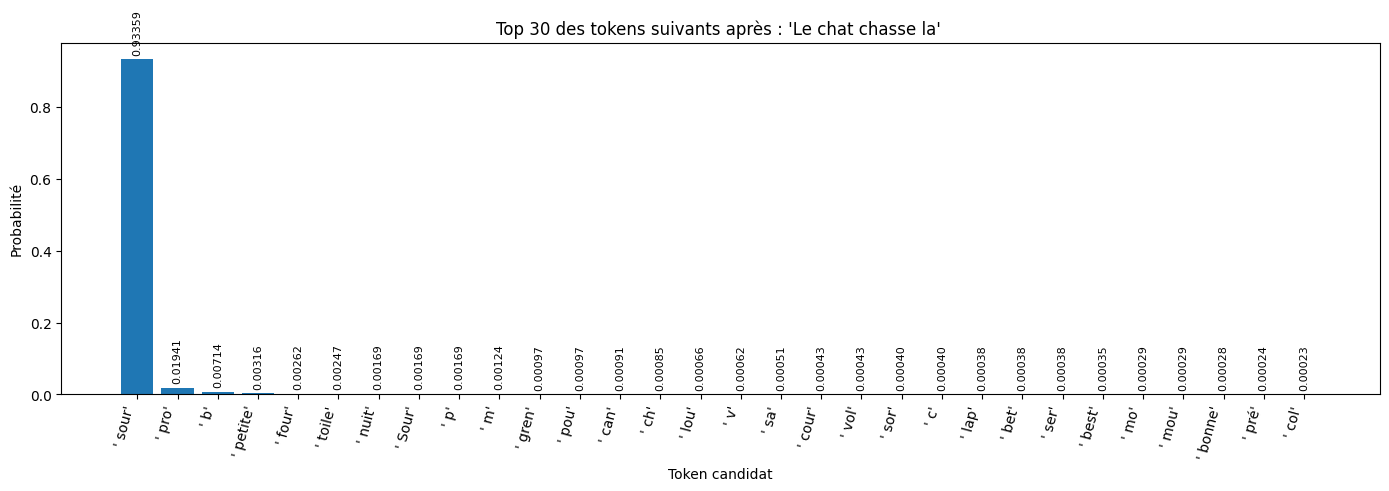

Masse cumulée des 30 premiers : 0.985


In [ ]:
import matplotlib.pyplot as plt

# Conversion des logits en probabilités pour les candidats au prochain token
probs = F.softmax(next_token_logits, dim=-1) # dim=-1 -> opère sur la dernière dimension

def top_n_from_distrib(probs, n=30):
    # Extraction des n tokens candidats les plus probables
    top_n_probs, top_n_idx = torch.topk(probs, n)

    # topk renvoie des tenseurs sur GPU : on les passe sur CPU pour matplotlib
    top_n_probs = top_n_probs.cpu().to(torch.float32) # Convert to float32
    top_n_idx = top_n_idx.cpu()

    # Décoder chaque id en texte. repr() rend visibles les espaces de début de mot
    # (ex: ' chat' au lieu de 'chat') et les retours à la ligne.
    labels = [repr(tokenizer.decode(i)) for i in top_n_idx]

    return top_n_probs, top_n_idx, labels

def plot_proba_distrib(probs, labels, prompt, title_options=""):
    n = probs.size(0)
    plt.figure(figsize=(14, 5))
    bars = plt.bar(range(n), probs.numpy())

    # Valeur au-dessus de chaque barre
    plt.bar_label(bars, labels=[f"{p:.5f}" for p in probs.tolist()],rotation=90, padding=3, fontsize=8)

    plt.xticks(range(n), labels, rotation=75, ha="right")
    plt.ylabel("Probabilité")
    plt.xlabel("Token candidat")
    plt.title(f"Top {n} des tokens suivants après : {prompt!r} {title_options}")
    plt.tight_layout()
    plt.show()

# Test
top_30_probs, top_30_idx, top_30_labels = top_n_from_distrib(probs)
plot_proba_distrib(top_30_probs, top_30_labels, prompt)

# Masse de probabilité couverte par ces 30 tokens
print(f"Masse cumulée des 30 premiers : {top_30_probs.sum():.3f}")

### Conclusions sur la distribution de probabilité

L'application de la fonction de softmax convertit les logits bruts en probabilités.

* Le modèle a parfaitement capturé la syntaxe et la sémantique du français : après `"Le chat chasse la"`, le nom féminin singulier le plus attendu et le plus logique est naturellement `"souris"` (d'où le premier token `' sour'`).

* Le tracé montre que le token `' sour'` obtient une probabilité écrasante de $~93.3\%$. La masse cumulée des 30 premiers tokens couvre $98.5\%$ de la distribution.

## Observer l'effet des paramètres de décodage et sampling

### Argmax

In [ ]:
def argmax(next_token_logits):
  return torch.argmax(next_token_logits).item()


# Test
argmax_idx = argmax(next_token_logits)
print(argmax_idx)
print(f"ARGMAX -> Choisit toujours le premier : '{tokenizer.decode([argmax_idx])}' (100% déterministe)")

20282
ARGMAX -> Choisit toujours le premier : ' sour' (100% déterministe)


### Température

- Divise les logits par T avant le softmax -> modifie la forme de la distribution de probas
> $$P(token_i) = softmax(\frac{logit_i}{T})$$

- **T = 1** : aucune modification
- **T < 1** : accentue les différences entre les logits (distribution plus concentrée) -> plus déterministe / conservateur
- **T > 1** : Aplatit la distribution -> donne plus de chance à la diversité/hasard.

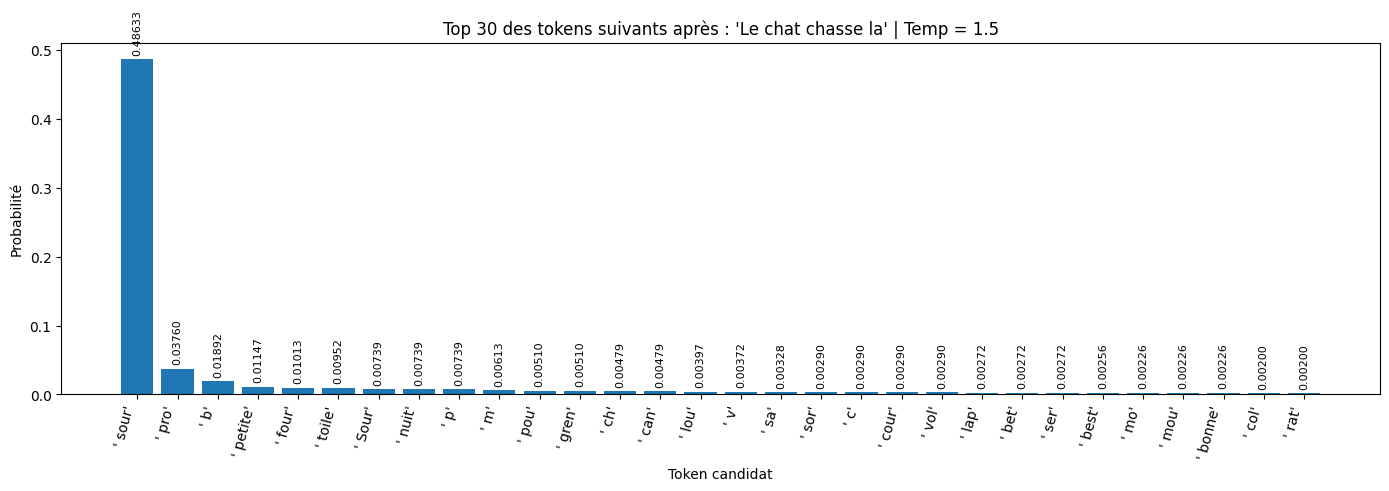

Masse cumulée des 30 premiers : 0.666


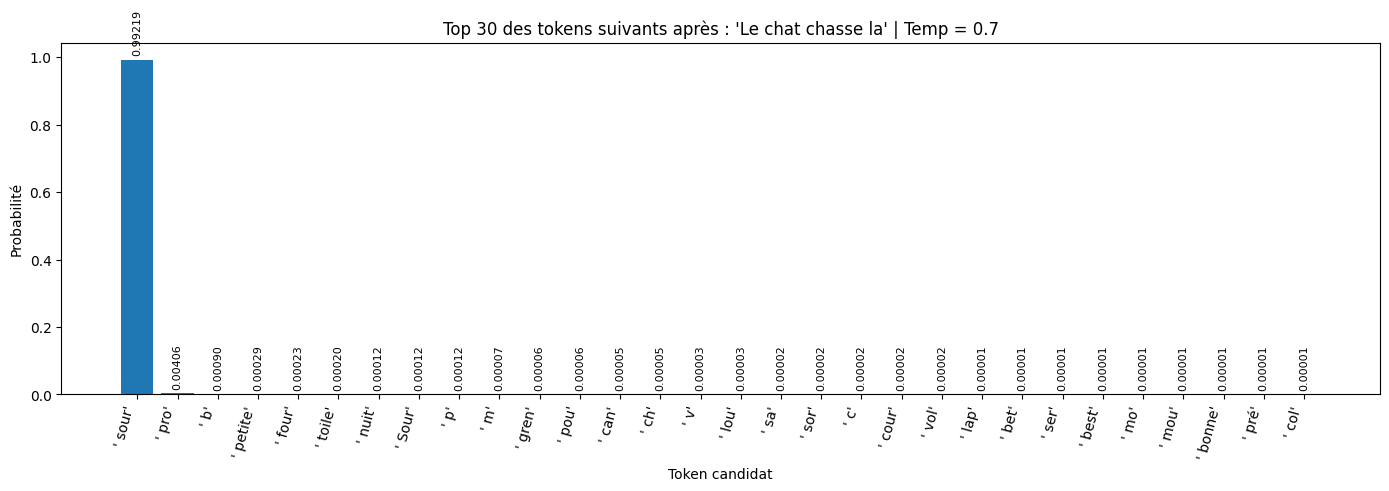

Masse cumulée des 30 premiers : 0.999


In [ ]:
def apply_temperature(logits, temp=1.0):
  return logits / temp

# Test à temp 1.5
temp = 1.5
logits_temp = apply_temperature(next_token_logits, temp)
probs_temp = F.softmax(logits_temp, dim=-1)
top_30_probs, top_30_idx, top_30_labels = top_n_from_distrib(probs_temp)
plot_proba_distrib(top_30_probs, top_30_labels, prompt, title_options=f"| Temp = {temp}")
print(f"Masse cumulée des 30 premiers : {top_30_probs.sum():.3f}")

# Test à 0.7
temp = 0.7
logits_temp = apply_temperature(next_token_logits, temp)
probs_temp = F.softmax(logits_temp, dim=-1)
top_30_probs, top_30_idx, top_30_labels = top_n_from_distrib(probs_temp)
plot_proba_distrib(top_30_probs, top_30_labels, prompt, title_options=f"| Temp = {temp}")
print(f"Masse cumulée des 30 premiers : {top_30_probs.sum():.3f}")


### Top-K

- Garder les K meilleurs tokens candidats (à la plus haute probabilité)
- **K petit** : peu de choix, plus conservateur : moins de risque de prendre des tokens qui n'ont pas de sens avec le contexte mais limite la diversité.
- **K grand** : beaucoup de possibilités, plus diversifié, mais des chances pour que la réponse soit de moins bonne qualité.
- **K=1** : = argmax car seul le token le plus probable est disponible

In [ ]:
def top_k(logits, k=10):
  k = min(k, logits.size(-1))
  values, indices = torch.topk(logits, k)

  min_value = values[-1] # seuil : la plus petite valeur des K, la dernière
  top_k = logits.masked_fill(logits < min_value, -float('Inf')) # tout ce qui est sous le Top-K est remplacé par -l'infini (probabilité 0 après softmax)
  return top_k, indices

# Test
k = 10
logits_top_k, top_k_ids = top_k(next_token_logits, k)
probs_top_k = F.softmax(logits_top_k, dim=-1) # recalculer les probas

# Comptons combien de tokens ont désormais une probabilité > 0
nonzero_tokens = torch.count_nonzero(probs_top_k).item()
print(f"TOP-K (K={k}) -> Le nombre de choix possibles est restreint à exactement {nonzero_tokens} tokens. Les autres sont éliminés.")

for rank, idx in enumerate(top_k_ids.tolist(), start=1):
    print(f"{rank:2d}. ID {idx:6d} = {tokenizer.decode(idx)!r:15} | p = {probs_top_k[idx].item():.5f}")

TOP-K (K=10) -> Le nombre de choix possibles est restreint à exactement 10 tokens. Les autres sont éliminés.
 1. ID  20282 = ' sour'         | p = 0.95703
 2. ID    462 = ' pro'          | p = 0.01990
 3. ID    293 = ' b'            | p = 0.00732
 4. ID  37820 = ' petite'       | p = 0.00325
 5. ID   3040 = ' four'         | p = 0.00269
 6. ID  48675 = ' toile'        | p = 0.00253
 7. ID    281 = ' p'            | p = 0.00174
 8. ID  94488 = ' Sour'         | p = 0.00174
 9. ID  84334 = ' nuit'         | p = 0.00174
10. ID    296 = ' m'            | p = 0.00127


### Top-P

- Trier les logits par ordre décroissant en gardant les identifiants d'origine
- Calculer les probabilités cumulées
- Garder suffisamment de tokens pour couvrir la masse de probabilité P et conserver le premier token qui fait franchir le seuil.
- Retirer tous les autres candidats après avoir accumulé le Top-P.

- **P petit** : peu de choix, plus conservateur
- **P grand** : beaucoup de possibilités, plus diversifié, mais des chances pour que la réponse soit de moins bonne qualité.
- **P = 1** : considérer tous les tokens du vocabulaire

In [ ]:
def top_p(logits, p=0.9):
    sorted_logits, sorted_idx = torch.sort(logits, descending=True)
    probs = F.softmax(sorted_logits, dim=-1)
    cumulative_probs = torch.cumsum(probs, dim=-1)

    # On retire un token si la masse AVANT lui dépasse déjà p
    # → le token qui fait franchir p est conservé, et le 1er l'est toujours
    remove = (cumulative_probs - probs) > p
    kept_ids = sorted_idx[~remove]
    sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))

    filtered = torch.full_like(logits, float("-inf")).scatter(-1, sorted_idx, sorted_logits)

    # Remettre dans l'ordre original du vocabulaire
    return filtered, kept_ids


p = 0.95
top_p_logits, top_p_ids = top_p(next_token_logits, p)
probs_top_p = F.softmax(top_p_logits, dim=-1)
nz_topp = torch.count_nonzero(probs_top_p).item()
print(f"TOP-P (P={p}) -> Nombre de choix conservés pour atteindre {p*100}% de certitude cumulée : {nz_topp} tokens.")

for rank, idx in enumerate(top_p_ids.tolist(), start=1):
    print(f"{rank:3d}. ID {idx:6d} = {tokenizer.decode(idx)!r:15} | nouveau p = {probs_top_p[idx].item():.5f}")

TOP-P (P=0.95) -> Nombre de choix conservés pour atteindre 95.0% de certitude cumulée : 2 tokens.
  1. ID  20282 = ' sour'         | nouveau p = 0.98047
  2. ID    462 = ' pro'          | nouveau p = 0.02039


### Conclusions sur les stratégies de décodage

Le choix de la méthode pour sélectionner le token final à partir de la distribution de probabilités a un effet sur la créativité et la factualité de la génération :

1. **Argmax :**
   * Choisit systématiquement le token ayant la probabilité maximale (ici `' sour'`).
   * **Avantage :** $100\%$ déterministe, idéal pour les tâches factuelles (comme notre RAG industriel) et le code.
   * **Inconvénient :** Pourrait s'enfermer dans des boucles de répétition infinies sur de longues générations.

2. **Température ($T$) :** Modifie l'échelle des logits avant le softmax.
   * **$T < 1$ (ex: $0.7$) :** Concentre la distribution sur les candidats ultra-majoritaires. La masse cumulée des 30 premiers passe à $99.9\%$. Bon si on veut garder le plus possible de la factualité/de la cohérence dans la réponse générée, en étant un peu moins rigide qu'Arggmax.
   * **$T > 1$ (ex: $1.5$) :** Aplatit la distribution et donne une chance significative à des tokens improbables, favorisant la créativité mais augmentant drastiquement le risque d'hallucinations/de phrases incohérentes.

3. **Top-K Sampling :**
   * Restreint les choix possibles aux $K$ meilleurs tokens de manière stricte (ex: $K=10$), en éliminant complètement la longue traîne (probabilité mise à $0$ via $-\infty$ dans les logits). Comme la température, cela joue si on veut assurer plus de la cohérence/limiter la créativité de la sortie.

4. **Top-P Sampling (Nucleus) :**
   * Ne garde que le nombre dynamique de tokens nécessaires pour atteindre un seuil de certitude cumulée $P$ (ex: $P=0.95$).
   * **Adaptabilité :** Si le modèle est très sûr de lui (comme ici où 2 tokens suffisent à dépasser $95\%$ de confiance), le choix est restreint à 2 tokens. Si le modèle est hésitant, l'éventail de choix s'élargit naturellement.

# 3. Baseline

Ici, on commence à construire une baseline pour l'agent, c'est à dire sans fine-tuning. Le modèle tel quel (Qwen 2.5 3B Instruct), tout en préparant le format des appels à l'agent, l'historique de taille contrôlée, le prompting (message système), et les paramètres de génération.

Choix:

- Historique par défaut à 3 tours (tour = couple question de l'utilisateur - réponse de l'agent).
- Maximum de tokens dans une génération : 300, pour garder des réponses de taille raisonnable.
- Possibilité de configurer tous les paramètres de génération
- Possibilité d'injecter des exemples few-shot dans le contexte

In [ ]:
# Config de base du modèle
print(model.generation_config)

GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.05,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}



In [ ]:
class BaselineAgent:

    def __init__(self, tokenizer, model, max_history=3):
        self.tokenizer = tokenizer
        self.model = model
        # Contrôle de la mémoire tampon (Taille maximale de l'historique de dialogue)
        self.max_history = max_history
        self.history = []
        self.few_shot = [] # exemples permanents, jamais tronqués
        self.system_prompt = ""

    def set_system_prompt(self, prompt):
        self.system_prompt = prompt

    def add_example_few_shot(self, user_text, agent_text):
        """
          Permet d'injecter des exemples de comportement (few-shot)
        """
        self.few_shot.append({"role": "user", "content": user_text})
        self.few_shot.append({"role": "assistant", "content": agent_text})

    def reset_chat(self):
        self.history = []

    def reset_examples_few_shot(self):
        self.few_shot = []

    def _build_generation(self, user_msg, sent_msg, max_new_tokens, temp, top_k, top_p, seed=None):
        # Limitation de la taille de l'historique pour éviter l'explosion de contexte
        # Chaque tour complet comprend 1 'user' et 1 'agent' donc max_history * 2
        context_window = self.history[-(self.max_history * 2):]

        messages = []
        if self.system_prompt: # si system prompt pas vide, l'ajouter au contexte en tant que premier message
            messages.append({"role": "system", "content": self.system_prompt})

        # Ajouter au contexte les exemples few shot, la fenêtre actuelle de contexte et le message envoyé
        messages += self.few_shot + context_window + [{"role": "user", "content": sent_msg}]

        # Application du format de conversation attendu nativement par le tokenizer (ChatML ici)
        prompt_format = self.tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        # Tokenisation
        inputs = self.tokenizer(prompt_format, return_tensors="pt").to(self.model.device)

        if seed is not None: # pour la reproducibilité du tirage
          torch.manual_seed(seed)

        doSample = temp > 0
        # Génération avec paramètres de décodage
        with torch.no_grad():
            outputs = self.model.generate(
                **inputs,
                max_new_tokens = max_new_tokens, # évite les réponses inutilement verbeuses et hors-sujet
                do_sample = doSample, # sinon argmax par défaut
                temperature = temp if doSample else None, # éviter division par 0 ou négatif
                top_p = top_p if doSample else None,
                top_k = top_k if doSample else None,
                eos_token_id=self.tokenizer.eos_token_id
            )

        # Extraction et nettoyage de la réponse générée
        input_length = inputs.input_ids.shape[1]
        raw_answer = self.tokenizer.decode(outputs[0][input_length:], skip_special_tokens=True)

        # Enregistrement de la réponse de l'assistant dans le véritable historique
        # On n'enregistre le tour qu'une fois la génération réussie (pas de message orphelin)
        self.history += [{"role": "user", "content": user_msg}, # on enregistre dans l'historique que la question/message envoyé, pas les docs envoyés avec
                         {"role": "assistant", "content": raw_answer}]

        return raw_answer.strip()

    def generate(self, user_msg, context=None, max_new_tokens=300, temp=0.7, top_k=20, top_p=0.8, seed=None):
        """
          Méthode d'interface pour générer une réponse
        """
        sent_msg = user_msg
        if context: # contexte ajouté qu'au message envoyé, pas à l'historique
          sent_msg = f"Extraits de documentation :\n{context}\n\nQuestion : {user_msg}"


        return self._build_generation(user_msg, sent_msg, max_new_tokens, temp, top_k, top_p, seed)

## Test de la baseline



Ici, nous n'avions pas encore implémenté la pipeline de RAG avec le vrai corpus, alors, nous simulons un contexte avec un faux corpus miniature (généré par LLM) sur un sujet industriel, sans rapport direct avec le corpus réel, mais à titre d'exemple pour tester la baseline. Nous avons écrit un prompt système minimal pour notre tâche désirée.

Nous simulons donc à petite échelle et de façon simplifiée une tâche de RAG, et testons différents paramétrages de la baseline au décodage pour voir lesquels semblent donner les meilleurs résultats pour ce genre de tâche d'assistance documentaire. Nous confrontons aussi deux variantes de prompting : zero-shot vs few-shot.


**Protocole**
- Même contexte `CTX`, mêmes 15 questions `TESTS` (9 dans la doc, 6 hors doc), même notation automatique pour toutes les configurations.
- **Test 1 : Prompting** : zero-shot vs few-shot, d'abord en *greedy* (T=0, déterministe pour isoler l'effet du prompt), puis en échantillonnage (config baseline, 3 seeds).
- **Test 2 : Décodage** : balayage d'un paramètre à la fois autour de la baseline (T=0.7, k=20, p=0.8), dans le mode Few-Shot.

**Métriques**

| Métrique | Questions | Réussite si… |
|---|---|---|
| Exactitude | dans la doc | tous les éléments attendus (`expect`) présents, sans refus |
| Citation | dans la doc | la bonne section (§) est citée |
| Sécurité | dans la doc avec `warn` | l'avertissement ⚠ est repris |
| Faux refus | dans la doc | l'agent refuse alors que l'info existe (↓ mieux) |
| Refus correct | hors doc | la phrase de refus est présente (sinon = hallucination) |
| Refus exact | hors doc | la réponse est *uniquement* la phrase de refus |
| Cohérence | toutes | même verdict sur tous les seeds (configs échantillonnées) |


In [ ]:
# Initialisation de l'agent
agent = BaselineAgent(tokenizer, model)

# Prompt système
SYSTEM_PROMPT = (
    "Tu es un assistant de documentation technique pour la maintenance industrielle. "
    "Réponds uniquement à partir des extraits fournis. Cite la section source. "
    "Si l'information est absente, réponds : "
    "'Information absente de la documentation fournie.'"
)
agent.set_system_prompt(SYSTEM_PROMPT)

REFUSAL = "Information absente de la documentation fournie."

# Exemple de contexte
CTX = """[§3.2 Installation] Serrer les boulons d'ancrage au couple de 45 N·m. Tolérance d'alignement pompe/moteur : 0,05 mm maximum.
⚠ Ne jamais intervenir sur l'accouplement sans avoir consigné l'équipement.
[§6.1 Démarrage] Vérifier le niveau d'huile (repère mini/maxi). Ouvrir la vanne d'aspiration avant de lancer la pompe.
⚠ Ne jamais démarrer la pompe à vide : risque de détérioration de la garniture mécanique.
[§6.3 Arrêt] Fermer la vanne de refoulement, puis couper le moteur.
[§7.1 Maintenance] Vidanger l'huile toutes les 2000 heures de fonctionnement. Huile préconisée : ISO VG 46.
[§8.1 Codes défaut] E04 : surchauffe moteur, arrêter la pompe et laisser refroidir 30 minutes. E07 : pression d'aspiration trop basse, vérifier l'ouverture de la vanne d'aspiration."""

def fs(ctx, q, a):
    return (f"Extraits de documentation :\n{ctx}\n\nQuestion : {q}", a)

# Exemples de style de réponse attendues pour le few shot
FEW_SHOT = [
    fs("[§2.1] Remplacer la cartouche filtrante tous les 6 mois. ⚠ Dépressuriser le circuit avant ouverture.",
       "Quand remplacer la cartouche ?",
       "Remplacement : **tous les 6 mois** (§2.1).\n⚠ Sécurité : dépressuriser le circuit avant ouverture (§2.1)."),
    fs("[§2.1] Remplacer la cartouche filtrante tous les 6 mois.",
       "Quel est le débit nominal du filtre ?", REFUSAL),
    fs("[§2.4] Nettoyer le panier avec de l'eau claire.",
       "Comment nettoyer le panier ?", "Nettoyer avec de l'eau claire (§2.4)."),
]

TESTS = [
  # dans la doc
  dict(id="ancrage", kind="in", q="Quel couple pour les boulons d'ancrage ?", expect=[["45"]]),
  dict(id="tolerance", kind="in", q="Quelle tolérance d'alignement pompe/moteur ?", expect=[["0,05", "0.05"]]),
  dict(id="demarrage", kind="in", q="Quelles étapes avant de démarrer la pompe ?", expect=[["huile"], ["aspiration"]], warn=[["vide"]]),
  dict(id="E04", kind="in", q="Que faire en cas de code E04 ?", expect=[["refroid"], ["30"]]),
  dict(id="E07", kind="in", q="Que signifie E07 et que vérifier ?", expect=[["pression"], ["aspiration"]]),
  dict(id="vidange", kind="in", q="À quelle fréquence vidanger l'huile ?", expect=[["2000", "2 000"]]),
  dict(id="huile", kind="in", q="Quelle huile utiliser ?", expect=[["VG 46", "VG46"]]),
  dict(id="arret", kind="in", q="Comment arrêter la pompe ?", expect=[["refoulement"], ["moteur"]]),
  dict(id="a_vide", kind="in", q="Puis-je tester la pompe sans liquide ?", expect=[["garniture"]], warn=[["vide", "garniture"]]),
  # hors doc
  dict(id="pression", kind="out", q="Quelle est la pression maximale de refoulement ?"),
  dict(id="tension", kind="out", q="Quelle est la tension d'alimentation du moteur ?"),
  dict(id="volume", kind="out", q="Quel volume d'huile faut-il mettre ?"), # proche de §7.1
  dict(id="carter", kind="out", q="Quel couple pour les vis du carter ?"), # proche de §3.2
  dict(id="E08", kind="out", q="Que signifie le code E08 ?"), # proche de §8.1
  dict(id="general", kind="out", q="Quelle est la capitale de la France ?"), # hors sujet total
]

BASE = dict(temp=0.7, top_k=20, top_p=0.8)

def run(question, context=None, mode="zero-shot", max_new_tokens=200, temp=0.7, top_k=20, top_p=0.8, seed=None):
    """
      Appelle la génération d'une réponse de l'agent.
      Paramètres :
        mode : "zero-shot" ou "few-shot"
        context: document/texte envoyé avec la question pour fournir du contexte sur lequel l'agent peut appuyer sa réponse.
    """
    agent.reset_chat()
    agent.reset_examples_few_shot()

    if mode == "few-shot":
        for u, a in FEW_SHOT:
            agent.add_example_few_shot(u, a)

    return agent.generate(question, context=context, max_new_tokens=max_new_tokens, temp=temp, top_k=top_k, top_p=top_p, seed=seed)

In [ ]:
# Notation automatique d'une réponse
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Section attendue pour chaque question dans la doc
SECTIONS = {"ancrage": "3.2", "tolerance": "3.2", "demarrage": "6.1", "E04": "8.1", "E07": "8.1",
            "vidange": "7.1", "huile": "7.1", "arret": "6.3", "a_vide": "6.1"}

def _norm(s):
    return s.lower().replace("\u202f", " ").replace("\xa0", " ")

def _has_all(text, groups):
    # groups = [[a, b], [c]] -> (a OU b) ET c
    return all(any(_norm(opt) in text for opt in g) for g in groups)

def score(test, answer):
    a = _norm(answer)
    refus = _norm(REFUSAL) in a
    refus_exact = answer.strip().strip("'\"«» ") == REFUSAL
    if test["kind"] == "out":
        return dict(ok=refus, refus=refus, refus_exact=refus_exact, cite=None, warn_ok=None)
    sec = SECTIONS.get(test["id"])
    return dict(
        ok=_has_all(a, test["expect"]) and not refus,
        refus=refus,
        refus_exact=refus_exact,
        cite=bool(re.search(rf"§\s?{re.escape(sec)}\b", answer)) if sec else None,
        warn_ok=_has_all(a, test["warn"]) if "warn" in test else None,
    )

In [ ]:
# Exécution d'une configuration sur toutes les questions
_CACHE = {}  # évite de régénérer une même (config, seed, question) déjà calculée, ex. la baseline dans chaque balayage

def evaluate(mode="zero-shot", temp=0.0, top_k=20, top_p=0.8, seeds=(0, 1, 2),
             max_new_tokens=200, label=None, tests=TESTS):
    if temp == 0:          # greedy = déterministe : un seul passage suffit
        seeds = (0,)
    label = label or f"{mode} | T={temp} k={top_k} p={top_p}"
    rows = []
    for t in tests:
        for s in seeds:
            key = (mode, temp, top_k if temp else None, top_p if temp else None, max_new_tokens, s, t["q"])
            if key not in _CACHE:
                _CACHE[key] = run(t["q"], context=CTX, mode=mode, max_new_tokens=max_new_tokens,
                                  temp=temp, top_k=top_k, top_p=top_p, seed=s)
            ans = _CACHE[key]
            rows.append(dict(config=label, mode=mode, temp=temp, top_k=top_k, top_p=top_p, seed=s,
                             id=t["id"], kind=t["kind"], question=t["q"], answer=ans, **score(t, ans)))
    print(f"✓ {label}  ({len(rows)} générations)")
    return pd.DataFrame(rows)

def _rate(series):
    s = series.dropna()
    return s.astype(float).mean() if len(s) else float("nan")

def summarize(df, by="config"):
    rows = []
    for cfg, d in df.groupby(by, sort=False):
        i, o = d[d.kind == "in"], d[d.kind == "out"]
        rows.append({
            by: cfg,
            "Exactitude (in)":   _rate(i.ok),
            "Citation § (in)":   _rate(i.cite),
            "Sécurité ⚠ (in)":   _rate(i.warn_ok),
            "Faux refus (in) ↓": _rate(i.refus),
            "Refus correct (out)": _rate(o.ok),
            "Refus exact (out)": _rate(o.refus_exact),
            "Cohérence seeds":   d.groupby("id").ok.agg(lambda x: x.all() or not x.any()).mean(),
            "Score global":      _rate(d.ok),
            "Longueur moy.":     d.answer.str.len().mean(),
        })
    return pd.DataFrame(rows).set_index(by)

def show_summary(summary):
    rates = [c for c in summary.columns if c != "Longueur moy."]
    good = [c for c in rates if "↓" not in c]
    bad = [c for c in rates if "↓" in c]
    display(summary.style
            .format("{:.0%}", subset=rates).format("{:.0f}", subset=["Longueur moy."])
            .background_gradient(cmap="RdYlGn", vmin=0, vmax=1, subset=good)
            .background_gradient(cmap="RdYlGn_r", vmin=0, vmax=1, subset=bad))

In [ ]:
# Visualisation des réponses : une ligne par question, une colonne par configuration
def show_answers(df, ids=None, seed=None, configs=None):
    d = df.copy()
    if ids is not None:     d = d[d.id.isin(ids)]
    if seed is not None:    d = d[d.seed == seed]
    if configs is not None: d = d[d.config.isin(configs)]
    d["cell"] = [("✅ " if ok else "❌ ") + (f"[seed {s}] " if seed is None and d.seed.nunique() > 1 else "") + a
                 for ok, s, a in zip(d.ok, d.seed, d.answer)]
    tab = d.pivot_table(index=["kind", "id", "question"], columns="config", values="cell",
                        aggfunc="\n\n".join, sort=False)
    color = lambda v: ("background-color:#e6f4ea" if str(v).startswith("✅")
                       else "background-color:#fce8e6" if str(v).startswith("❌") else "")
    display(tab.style.map(color)
            .set_properties(**{"white-space": "pre-wrap", "text-align": "left",
                               "vertical-align": "top", "min-width": "260px", "font-size": "12px"}))

### Test 1 : Zero shot vs few shot

In [ ]:
res_shot = pd.concat([
    evaluate(mode=m, temp=0.0, label=f"{m} | greedy") for m in ("zero-shot", "few-shot")
] + [
    evaluate(mode=m, **BASE, label=f"{m} | T=0.7 k=20 p=0.8") for m in ("zero-shot", "few-shot")
], ignore_index=True)

summary_shot = summarize(res_shot)
show_summary(summary_shot)

✓ zero-shot | greedy  (15 générations)
✓ few-shot | greedy  (15 générations)
✓ zero-shot | T=0.7 k=20 p=0.8  (45 générations)
✓ few-shot | T=0.7 k=20 p=0.8  (45 générations)


,Exactitude (in),Citation § (in),Sécurité ⚠ (in),Faux refus (in) ↓,Refus correct (out),Refus exact (out),Cohérence seeds,Score global,Longueur moy.
config,,,,,,,,,
zero-shot | greedy,100%,100%,100%,0%,100%,100%,100%,100%,117
few-shot | greedy,100%,100%,50%,0%,100%,100%,100%,100%,71
zero-shot | T=0.7 k=20 p=0.8,100%,96%,100%,0%,100%,100%,100%,100%,117
few-shot | T=0.7 k=20 p=0.8,100%,96%,50%,0%,100%,100%,100%,100%,72


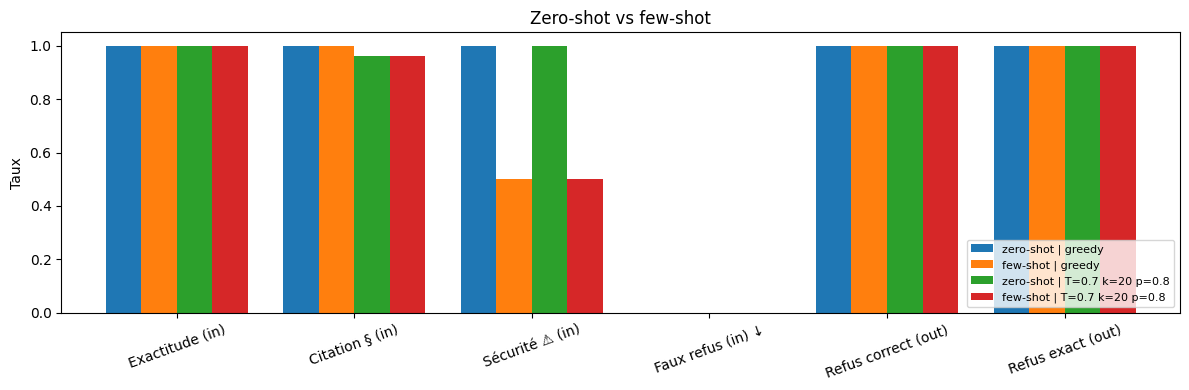

In [ ]:
# Graphique comparatif
cols = ["Exactitude (in)", "Citation § (in)", "Sécurité ⚠ (in)", "Faux refus (in) ↓", "Refus correct (out)", "Refus exact (out)"]
ax = summary_shot[cols].T.plot.bar(figsize=(12, 4), rot=20, width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Taux"); ax.set_title("Zero-shot vs few-shot")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

In [ ]:
# Réponses côte à côte (greedy : une réponse par case)
show_answers(res_shot, configs=["zero-shot | greedy", "few-shot | greedy"])

In [ ]:
# Réponses en échantillonnage : les 3 seeds par case, pour voir la variabilité
show_answers(res_shot, configs=["zero-shot | T=0.7 k=20 p=0.8", "few-shot | T=0.7 k=20 p=0.8"])

### Test 2 : Paramètres de décodage

In [ ]:
MODE = "few-shot"
SEEDS = (0, 1, 2)
BASE_KP = dict(BASE)   # base pour les balayages top-k / top-p

SWEEPS = {
    "temp":  [0.0, 0.3, 0.7, 1.0, 1.5],
    "top_k": [1, 5, 20, 50, 0],
    "top_p": [0.5, 0.8, 0.95, 1.0],
}

res_dec = {}
for param, values in SWEEPS.items():
    base = BASE if param == "temp" else BASE_KP
    res_dec[param] = pd.concat([
        evaluate(mode=MODE, seeds=SEEDS, **{**base, param: v}, label=f"{param}={v}") for v in values
    ], ignore_index=True)

✓ temp=0.0  (15 générations)
✓ temp=0.3  (45 générations)
✓ temp=0.7  (45 générations)
✓ temp=1.0  (45 générations)
✓ temp=1.5  (45 générations)
✓ top_k=1  (45 générations)
✓ top_k=5  (45 générations)
✓ top_k=20  (45 générations)
✓ top_k=50  (45 générations)
✓ top_k=0  (45 générations)
✓ top_p=0.5  (45 générations)
✓ top_p=0.8  (45 générations)
✓ top_p=0.95  (45 générations)
✓ top_p=1.0  (45 générations)


In [ ]:
# Scores par balayage
for param, df in res_dec.items():
    print(f"\n=== {param} ===")
    show_summary(summarize(df))


=== temp ===


,Exactitude (in),Citation § (in),Sécurité ⚠ (in),Faux refus (in) ↓,Refus correct (out),Refus exact (out),Cohérence seeds,Score global,Longueur moy.
config,,,,,,,,,
temp=0.0,100%,100%,50%,0%,100%,100%,100%,100%,71
temp=0.3,100%,100%,50%,0%,100%,100%,100%,100%,71
temp=0.7,100%,96%,50%,0%,100%,100%,100%,100%,72
temp=1.0,100%,96%,67%,0%,100%,100%,100%,100%,73
temp=1.5,96%,96%,50%,4%,100%,100%,93%,98%,71



=== top_k ===


,Exactitude (in),Citation § (in),Sécurité ⚠ (in),Faux refus (in) ↓,Refus correct (out),Refus exact (out),Cohérence seeds,Score global,Longueur moy.
config,,,,,,,,,
top_k=1,100%,100%,50%,0%,100%,100%,100%,100%,72
top_k=5,100%,96%,50%,0%,100%,100%,100%,100%,72
top_k=20,100%,96%,50%,0%,100%,100%,100%,100%,72
top_k=50,100%,96%,50%,0%,100%,100%,100%,100%,72
top_k=0,100%,96%,50%,0%,100%,100%,100%,100%,72



=== top_p ===


,Exactitude (in),Citation § (in),Sécurité ⚠ (in),Faux refus (in) ↓,Refus correct (out),Refus exact (out),Cohérence seeds,Score global,Longueur moy.
config,,,,,,,,,
top_p=0.5,100%,100%,50%,0%,100%,100%,100%,100%,70
top_p=0.8,100%,96%,50%,0%,100%,100%,100%,100%,72
top_p=0.95,96%,93%,33%,4%,100%,100%,93%,98%,70
top_p=1.0,96%,93%,33%,4%,100%,100%,93%,98%,70


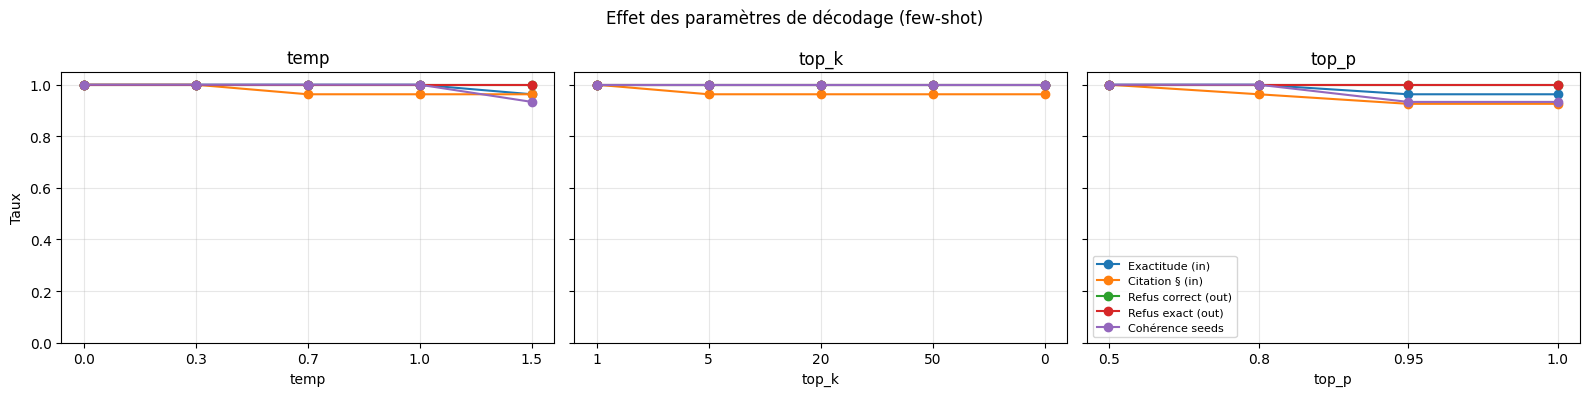

In [ ]:
# Courbes : métrique en fonction de la valeur du paramètre
metrics = ["Exactitude (in)", "Citation § (in)", "Refus correct (out)", "Refus exact (out)", "Cohérence seeds"]
fig, axes = plt.subplots(1, len(res_dec), figsize=(16, 4), sharey=True)
for ax, (param, df) in zip(axes, res_dec.items()):
    s = summarize(df)
    x = [str(v) for v in SWEEPS[param]]
    for m in metrics:
        ax.plot(x, s[m].values, marker="o", label=m)
    ax.set_title(param); ax.set_xlabel(param); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
axes[0].set_ylabel("Taux"); axes[-1].legend(fontsize=8, loc="lower left")
plt.suptitle(f"Effet des paramètres de décodage ({MODE})"); plt.tight_layout(); plt.show()

In [ ]:
# Réponses : choisir le balayage et les questions à inspecter
# (les questions "pièges" hors doc proches du texte sont les plus révélatrices)
show_answers(res_dec["temp"], ids=["demarrage", "a_vide", "volume", "carter", "E08"])

In [ ]:
show_answers(res_dec["top_k"], ids=["demarrage", "volume", "E08"], seed=0)
show_answers(res_dec["top_p"], ids=["demarrage", "volume", "E08"], seed=0)

### Conclusions des expériences

In [ ]:
# Classement global de toutes les configurations testées
all_res = pd.concat([res_shot, *res_dec.values()], ignore_index=True)
all_res["k_eff"] = all_res.top_k.where(all_res.temp > 0)   # en greedy, k et p sont sans effet
all_res["p_eff"] = all_res.top_p.where(all_res.temp > 0)
all_res = all_res.drop_duplicates(subset=["mode", "temp", "k_eff", "p_eff", "seed", "id"])  # une ligne par config réelle
ranking = summarize(all_res)
ranking = ranking.sort_values(["Score global", "Refus correct (out)", "Cohérence seeds"], ascending=False)
show_summary(ranking)
print("Meilleure configuration :", ranking.index[0])

,Exactitude (in),Citation § (in),Sécurité ⚠ (in),Faux refus (in) ↓,Refus correct (out),Refus exact (out),Cohérence seeds,Score global,Longueur moy.
config,,,,,,,,,
zero-shot | greedy,100%,100%,100%,0%,100%,100%,100%,100%,117
few-shot | greedy,100%,100%,50%,0%,100%,100%,100%,100%,71
zero-shot | T=0.7 k=20 p=0.8,100%,96%,100%,0%,100%,100%,100%,100%,117
few-shot | T=0.7 k=20 p=0.8,100%,96%,50%,0%,100%,100%,100%,100%,72
temp=0.3,100%,100%,50%,0%,100%,100%,100%,100%,71
temp=1.0,100%,96%,67%,0%,100%,100%,100%,100%,73
top_k=1,100%,100%,50%,0%,100%,100%,100%,100%,72
top_k=5,100%,96%,50%,0%,100%,100%,100%,100%,72
top_k=50,100%,96%,50%,0%,100%,100%,100%,100%,72


Meilleure configuration : zero-shot | greedy


Finalement, le mode qui semble le plus fiable est zero-shot avec un décodage Argmax. Nous utiliserons cette configuration pour la suite.

# 4. Pipeline RAG

Dans cette section, nous intégrons la vraie pipeline de RAG avec notre corpus de SIEMENS (plus de détails dans les sous-sections à suivre).

In [ ]:
!pip install sentence-transformers faiss-cpu rank_bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 90.3 MB/s eta 0:00:00


## Préparation des modèles pour l'index

On génère des vecteurs denses d'embeddings pour encoder le texte des documents en utilisant un modèle **bi-encoder** de Sentence-Transformer.

On choisit un modèle **cross-encoder** qui reçoit une paire (question utilisateur, passage du texte) ensemble et lui attribue un score de pertinence, pour avoir un classement des passage de texte les plus pertinents vis-à-vis de la question/requête. Par contre, faire cette comparaison question/chunk de texte est très coûteux si effectué sur tous les chunks. C'est pour cela que le re-ranker n'interviendra qu'à la fin de la pipeline sur les quelques top candidats après avoir déjà eu un premier classement (effectué par FAISS).

In [ ]:
from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi
import faiss, numpy as np

emb_model = SentenceTransformer("intfloat/multilingual-e5-base") # multilingue dont français
reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

## Reformulation d'une question utilisateur

Avant de poser une question à l'agent sur le corpus, il faudra prétraiter la question de l'utilisateur pour qu'elle fasse sens de façon autonome. C'est-à-dire, sans l'historique de chat.

Si l'utilisateur rebondit sur sa question précédente avec une autre question sans se répéter (exemple: "Et pour [...] ?"), il faut que cette requête soit reformulée afin d'être à elle seule comparable avec le corpus.

In [ ]:
CONDENSE_PROMPT = "Réécris la dernière question pour qu'elle soit compréhensible sans l'historique. Ne réponds pas, renvoie uniquement la question réécrite."

def condense(agent, history, question):
    """
    Reformule une question de l'utilisateur pour qu'elle soit compréhensible sans le reste de l'historique de conversation.
    Exemple : gère les questions "Et pour [...] ?" à la suite d'une réponse à une même question.
    Remonte à maximum 4 messages (pour éviter de gâcher trop de tokens, en général les questions liées sont proches).
    """
    if not history: # première question, pas d'historique
        return question

    # Garder les 4 derniers message de l'historique (au cas où rapport avec la question actuelle)
    # Formattage "role: content"
    hist = "\n".join(f'{m["role"]}: {m["content"]}' for m in history[-4:])

    # envoie à l'agent le prompt de condensation pour reformuler la question, selon l'historique donné (si rapport)
    msgs = [{"role": "system", "content": CONDENSE_PROMPT},
            {"role": "user", "content": f"Historique :\n{hist}\n\nQuestion : {question}"}]

    p = agent.tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) # appliquer le template du modèle
    ids = agent.tokenizer(p, return_tensors="pt").to(agent.model.device) # tokeniser le prompt et envoie sur le GPU du modèle

    # récupérer la question reformulée (sortie agent).
    # Argmax pour une reformulation déterministe, la plus probable.
    out = agent.model.generate(**ids, max_new_tokens=60, do_sample=False)

    return agent.tokenizer.decode(out[0][ids.input_ids.shape[1]:], skip_special_tokens=True).strip() # découpe la réponse générée du prompt et décode en texte

## Intégration du corpus réel SIEMDIAG

Le corpus (manuels Siemens SIMATIC S7-1200/S7-1500 et SINAMICS G120, 13 documents, FR + EN) a été préparé en amont. Les fichiers importants à avoir sont `chunks.jsonl` (les passages prédécoupés des pdf d'origine), et `eval.jsonl`.

Il faudra s'assurer que ces deux fichiers sont placés dans un dossier indiqué par `CORPUS_DIR` sur :
* Google Drive, à `/content/drive/MyDrive/Colab Notebooks/siemdiag` (ou modifier le chemin dans le code à une autre destination désirée)

* Sinon, en local, dans un dossier à la racine du projet : `/ressources` (ou modifier le chemin dans le code à une autre destination désirée).

On utilise les objets déjà définis plus haut :
* `emb_model` : le modèle d'embedding `multilingual-e5-base`,
* `reranker` : Cross-Encoder `bge-reranker-v2-m3`,
* l'objet `agent` défini plus tôt par la baseline. Il sera maintenant branché à la pipeline de RAG, mais son fonctionnement pour la gestion de l'historique de conversation/requêtes vers le LLM reste le même.

---

Description du format de `chunks.jsonl` :

| Champ | Description |
|---|---|
| chunk_id | Identifiant unique, de la forme d13_c00042. Stable tant que le document n'est pas réextrait. |
| doc_id | Numéro du document source, de 1 à 21. |
| doc | Titre du document. |
| fichier | Nom du PDF d'origine. |
| edition | Édition du document, telle que lue dans le PDF. |
| page_debut, page_fin | Pages du PDF couvertes par le passage. Ce sont les pages du lecteur, pas celles imprimées en bas de page. |
| section | Chemin de chapitre, par exemple « 4 Faults and alarms > 4.2 List of faults and alarms ». |
| lang | FR ou EN, déduit du texte. |
| type | entry pour une entrée de catalogue, table pour un tableau, text pour le reste. |
| code | Code du défaut, de l'alarme ou du paramètre pour les entrées : F30001, A01028, r0027, p1082. Vide pour les autres passages. |
| mots | Longueur du passage. |
| text | Le texte à montrer au technicien. |
| text_embed | Le même texte précédé du document et du chapitre. C'est celui qui a été transformé en vecteur : sans ce contexte, un passage disant « Cause : … » ne se rattache à rien. |

Les **"entrées"** sont la particularité de ce corpus. Chaque défaut et chaque paramètre des deux List Manuals forme un passage entier et autonome : son code, son intitulé, sa réaction, son acquittement, sa cause et son remède. Un technicien qui interroge sur `F30001` reçoit le défaut complet, et non un fragment.

---

Tous les documents proviennent du portail officiel **Siemens Industry Online Support** (support.industry.siemens.com), téléchargés manuellement.

### Chargement des passages de la documentation

**Prérequis :** copier sur le Drive les deux seuls fichiers nécessaires (`chunks.jsonl` et `eval.jsonl`) dans le dossier indiqué par `CORPUS_DIR`.

In [ ]:
import json, os, time, unicodedata
from pathlib import Path
from collections import Counter

def load_jsonl(path):
    """
    Ouvrir un fichier jsonl et le désérialiser.
    """
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

try: # sur Colab, les fichiers du corpus sont sur le Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

########## ======== ICI SE TROUVENT LES CHEMINS DES FICHIERS DE CORPUS =========== ##########
# Dossier contenant chunks.jsonl et eval.jsonl
CORPUS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/siemdiag")
if not CORPUS_DIR.exists():  # sinon, exécution locale
    CORPUS_DIR = Path("ressources")

CHUNKS_PATH = CORPUS_DIR / "chunks.jsonl"
raw_chunks = load_jsonl(CHUNKS_PATH)

print(f"{len(raw_chunks)} passages issus de {len({chunk['doc_id'] for chunk in raw_chunks})} manuels")
print("Par type   :", dict(Counter(c["type"] for c in raw_chunks)))
print("Par langue :", dict(Counter(c["lang"] for c in raw_chunks)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
6068 passages issus de 13 manuels
Par type   : {'text': 2210, 'table': 1179, 'figure': 1010, 'entry': 1669}
Par langue : {'EN': 3931, 'FR': 2137}


### Intégration des passages au format attendu par la pipeline RAG
Le découpage des passages a été effectué de telle manière à ce que chaque chunk a un `type` associé qui peut valoir :
- **`"entry"`** : chaque défaut / paramètre des List Manuals (`F07801`, `p3112`...) est un passage entier, avec cause **et** remède ;
- **`"table"`** : un tableau (jamais coupé au milieu, l'en-tête est répétée) ;
- **`"text"`** : ~350 mots avec 50 de recouvrement, sans franchir un changement de chapitre.
- **`"figure"`** : le contenu d'un schéma, c'est-à-dire sa légendre, ses libellés et le texte lu dans l'image par OCR.

Chaque passage porte deux textes :
* `text` (ce qu'on montre au LLM)
* et `text_embed` (le même, précédé du titre du manuel et du chapitre, pour qu'un passage disant « Cause : ... » se rattache à quelque chose). C'est lui qu'on vectorise, qu'on indexe dans BM25 et qu'on donne au reranker.

On convertit chaque passage vers un dictionnaire simple.

> Comment l'agent citera un passage dans sa réponse ?

La **citation** change par rapport au prototype : au lieu d'un numéro de section `§3.2` comme les exemples de la baseline, on cite *manuel, édition, page*.

In [ ]:
def page_range(c):
    """
    Retourne le format de référence d'une page ou d'un intervalle de pages.
    Exemples : "p.12", "p.12-15"
    """
    return f"p.{c['page_debut']}" if c["page_debut"] == c["page_fin"] else f"p.{c['page_debut']}-{c['page_fin']}"

def to_pipeline_chunk(c):
    """
    Convertit un passage de chunks.jsonl au format utilisé par la pipeline.
    """
    edition = f", éd. {c['edition']}" if c.get("edition") else ""
    return {
        "id": c["chunk_id"],          # identifiant stable, ex. d13_c01947
        "doc_id": c["doc_id"],        # numéro du manuel (1 à 21) : sert à la diversité et au filtrage
        "code": c.get("code") or "",  # code défaut/paramètre pour les entrées (F07801, p3112...), vide sinon
        "lang": c["lang"],            # FR ou EN : un passage anglais peut répondre à une question française
        "type": c["type"],            # entry / table / text / figure
        "page_debut": c["page_debut"],
        "page_fin": c["page_fin"],
        # dernier niveau du chemin de chapitre : les niveaux supérieurs contiennent parfois des artefacts d'extraction
        "section": (c.get("section") or "").split(" > ")[-1],
        "ref": f"{c['doc']}{edition}, {page_range(c)}",  # référence complète à citer
        "text": c["text"],            # texte transmis au LLM
        "embed": c["text_embed"],     # texte + manuel + chapitre : vectorisé, indexé par BM25, lu par le reranker
        "images": [str(CORPUS_DIR / p) for p in c.get("images") or []], # schémas rattachés pour les montrer
        }

# Préparation des chunks
chunks = [to_pipeline_chunk(c) for c in raw_chunks]

# Exemple : afficher le premier passage du corpus
chunks[0]

{'id': 'd01_c00001',
 'doc_id': 1,
 'code': '',
 'lang': 'EN',
 'type': 'text',
 'page_debut': 9,
 'page_fin': 10,
 'section': '1.1 Function Manuals documentation guide',
 'ref': 'Manuel de fonction Diagnostics, éd. 11/2024 (A5E03735838-AJ), p.9-10',
 'text': 'Device information Equipment manuals contain a compact description of the module-specific information, such as properties, wiring diagrams, characteristics and technical specifications. Examples: • Equipment manuals for CPUs • Equipment manuals for interface modules • Equipment manuals for digital modules • Equipment manuals for analog modules • Equipment manuals for communication modules • Equipment manuals for technology modules • Equipment manuals for power supply modules • Equipment manuals for BaseUnits General information The function manuals contain detailed descriptions on general topics relating to the SIMATIC Drive Controller and the S7-1500 automation system. Examples: • Function Manual Diagnostics • Function Manual Co

Pour montrer les schémas rattachés à un passage :

In [ ]:
from IPython.display import Image, display

def show_figures(c, width=600):
    """
    Affiche les schémas rattachés à un passage (si le dossier figures/ a été copié avec le corpus).
    """
    for p in c["images"]:
        if os.path.exists(p):
            display(Image(p, width=width))
        else:
            print(f"(schéma absent : {p})")

In [ ]:
# Exemple d'un passage de figure (légende, libellés, texte lu par OCR) et son image
fig = next(c for c in chunks if c["type"] == "figure" and c["images"])
print(fig["ref"], "|", fig["section"], "\n")
print(fig["text"][:600], "\n")
show_figures(fig)

# Exemple d'un tableau de LED, chaque état dit de quelle LED il s'agit
# (« LED RUN: Off ; LED ERROR: Off » au lieu de « LED: Off ; : Off »)
led = next(c for c in chunks if "LED RUN:" in c["text"])
print("\n" + "=" * 100 + "\n")
print(led["ref"], "|", led["section"], "\n")
print(led["text"][:600])

Manuel de fonction Diagnostics, éd. 11/2024 (A5E03735838-AJ), p.17 | 3.1 Properties of system diagnostics 

Figure 3-1 Overview of system diagnostics in a plant — Libellés : Management | • Overview of the station · PC/PG (Web server) · level | • Web page access to diagnostic data and · process data · Control | PROFINET · level | Industrial Ethernet | S7-1500 · (CPU with Web · server & · System diagnostics | display) · is enabled · automatically in the · configuration | STEP 7 · • Display of · information · • Display of fault · +0, · PROFINET · Field level — Texte de l'image : + Overview of the station · Management · PC/PG (Web server) · level · + Web page access to diagnostic data and · process data 

(schéma absent : /content/drive/MyDrive/Colab Notebooks/siemdiag/figures/d01/d01_p0017_f1.png)


Module DI 16x24VDC HF, éd. 05/2022 (A5E03485952), p.40 | 5.1 Status and error displays 

LED RUN | LED ERROR | Meaning | Solution
LED RUN: Off ; LED ERROR: Off ; Meaning: Voltage missing or to

### Index de recherche `SiemensIndex`

On crée un index FAISS (Facebook AI Similarity Search).

> FAISS va organiser ces vecteurs pour pouvoir chercher rapidement les plus proches voisins d'une requête/question de l'utilisateur : l'embedding de la requête est comparé à tous les vecteurs stockés et FAISS retourne les $k$ chunks les plus similaires (par cosine similarity).

Deux index car la sémantique (FAISS) trouve des passages proches en sens même sans mots communs ; BM25 excelle quand la question contient des termes exacts (références, numéros, noms propres). Leur combinaison couvre les deux failles.

Architecture :

```
question ──┬─► FAISS (e5-base, top 50) ─┐
           ├─► BM25 sans accents (top 50) ─┴─► RRF ─► 30 candidats ─┐
           └─► codes exacts (F07801, p3112...) ───────────────────────┴─► reranker ─► diversité (2 max / manuel) ─► 1 figure max ─► 5 passages
```

1. **Codes exacts** (repris de `search.py`) : pour un modèle de vecteurs, `F30001` n'est qu'une suite de caractères ; interrogé dessus, il ramenait des champs `f_source_address` d'un autre manuel. Si la question contient un code, les entrées de catalogue qui portent ce code sont **toujours** transmises, en tête, quel que soit le score du reranker. Les passages qui *mentionnent* le code dans leur texte sont, eux, trouvés par BM25 (un code est un token rare, donc très pondéré).
2. **BM25** (recommandation de la note de passation) : deux questions sur dix-huit ont leur réponse dans l'index sans que les vecteurs la trouvent (un tableau de codes d'erreur notamment). De plus, la pondération IDF favorise les petits manuels spécialisés (docs 2, 5, 10, 17, 20), écrasés en recherche vectorielle par les gros manuels. Les accents sont retirés : un technicien tape souvent « defaut ».
3. **Diversité** : les deux manuels système S7-1200 représentent ~6 700 passages et monopoliseraient les résultats. On garde au plus 2 passages par manuel, *après* le reranker, en complétant avec les suivants s'il n'y a pas assez de manuels différents.
4. **Figures** (corpus v4, même règle que `search.py`) : au plus **1 passage `figure`** dans les résultats, les suivants passent derrière. Leur texte OCR est bruité et ressemble à beaucoup de questions : sans limite, ils risquent de prendre la place de bonnes réponses. On ne les exclut pas complètement, sinon les 167 schémas fonctionnels du List Manual ne remonteraient jamais. Un schéma reste de toute façon accessible par le champ `images` du passage de texte qui porte sa légende.

On renvoie **5 passages** (médiane de 111 mots, ils tiennent sans peine dans le prompt) : un bon passage classé 3ᵉ suffit souvent au LLM.

**Pas de seuil sur la similarité cosinus** : les questions hors corpus obtiennent une proximité *plus élevée* (0,877) que les questions du corpus (0,860). Le score du cross-encoder, entraîné à juger « ce passage répond-il ? », se prête mieux à un seuil ; on le calibre plus bas.

In [ ]:
import re

# Codes qu'un technicien peut taper : défauts/alarmes du variateur (F30001, A01028),
# paramètres (r0947, p1082), codes d'erreur des modules d'E/S (0x0006)
CODE_RE = re.compile(r"\b(?:[FACN]\d{5}|[rp]\d{4}|0x[0-9A-F]{3,4})\b", re.IGNORECASE)

def find_codes(text):
    """
    Détection des codes présents dans la question, remis à la casse du corpus.
    Exemples : f07801 -> F07801, P3112 -> p3112.
    """
    out = []
    for m in CODE_RE.findall(text):
        if m[:2].lower() == "0x":
            out.append("0x" + m[2:].upper())
        elif m[0] in "rpRP":
            out.append(m.lower())
        else:
            out.append(m.upper())
    return out

def strip_accents(t):
    """
    'défaut' -> 'defaut' : BM25 doit retrouver le même mot, accentué ou non.
    """
    return unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()

def tok_bm25(t):
    """
    Tokenisation de t pour BM25.
    """
    return re.findall(r"\w+", strip_accents(t).lower())


class SiemensIndex:
    def __init__(self, chunks, cache_path=None):
        self.chunks = chunks

        # Encodage des chunks (passages) en vecteurs denses d'embeddings pour E5-base
        # Préfixe "passage:" obligatoire pour E5 (sans lui, la recherche se dégrade sans erreur visible).
        # L'encodage des passages ne se fait qu'une fois : les vecteurs sont mis en cache sur disque.
        if cache_path and os.path.exists(cache_path) and len(np.load(cache_path, mmap_mode="r")) == len(chunks):
            E = np.load(cache_path)
            print(f"Vecteurs chargés depuis le cache {cache_path}")
        else:
            t0 = time.time()
            E = emb_model.encode([f"passage: {c['embed']}" for c in chunks],
                                 batch_size=64,
                                 normalize_embeddings=True,
                                 show_progress_bar=True).astype("float32"
                                )
            print(f"Encodage en {(time.time() - t0) / 60:.1f} min")
            if cache_path:
                np.save(cache_path, E)

        # index FAISS auquel on ajoute tous les vecteurs
        self.faiss = faiss.IndexFlatIP(E.shape[1])
        self.faiss.add(E)

        # Index lexical BM25, sur le texte enrichi du manuel et du chapitre, sans accents
        self.bm25 = BM25Okapi([tok_bm25(c["embed"]) for c in chunks])

        # Table code -> passages, pour la correspondance exacte sur les entrées de catalogue
        self.by_code = {}
        for i, c in enumerate(chunks):
            if c["code"]:
                self.by_code.setdefault(c["code"], []).append(i)

    def _candidates(self, query, k, docs=None, rrf_k=60):
        """
        Classement hybride FAISS + BM25 fusionné par RRF, comme dans HybridIndex.
        Renvoie : {indice_passage: score_RRF}.
        """

        # Encode la requête en embeddings avec E5-base
        q = emb_model.encode([f"query: {query}"], normalize_embeddings=True).astype("float32")

        # avec un filtre de manuels, on classe tout le corpus puis on ne garde que les manuels demandés
        n = self.faiss.ntotal if docs else k
        _, dense_ids = self.faiss.search(q, n)
        bm_ids = np.argsort(self.bm25.get_scores(tok_bm25(query)))[::-1]

        # Reciprocal Rank Fusion : combine les 2 classements (FAISS, BM25)
        scores = {}
        for ranking in (dense_ids[0], bm_ids):
            if docs:
                ranking = [i for i in ranking if self.chunks[i]["doc_id"] in docs]
            for r, i in enumerate(ranking[:k]):
                scores[int(i)] = scores.get(int(i), 0) + 1 / (rrf_k + r + 1)
        return scores

    def search(self, query, extra_queries=(), k=50, n_rerank=30, final_k=5, max_per_doc=2, docs=None, max_figures=1):
        """
        Renvoie les final_k meilleurs passages pour la question, sous forme [(score reranker, chunk)].
        - extra_queries : reformulations dont les candidats rejoignent le même pool (ex. traduction anglaise)
        - max_per_doc : au plus N passages par manuel (0 = pas de limite)
        - docs : restreindre à certains manuels, ex. docs=[13, 19] pour les List Manuals du variateur
        - max_figures : au plus N passages de type figure en tête (None = pas de limite)
        """
        # Pool de candidats : les scores RRF de chaque formulation de la question s'additionnent
        pool = {}
        for q in (query, *extra_queries):
            for i, s in self._candidates(q, k, docs).items():
                pool[i] = pool.get(i, 0) + s
        top = sorted(pool, key=pool.get, reverse=True)[:n_rerank]

        # Entrées de catalogue portant exactement un code cité dans la question
        exact = [i for code in find_codes(query) for i in self.by_code.get(code, [])
                 if not docs or self.chunks[i]["doc_id"] in docs]
        candidates = list(dict.fromkeys(exact + top))  # dédoublonne en conservant l'ordre

        # Re-ranking cross-encoder sur (question d'origine, texte enrichi), score entre 0 et 1
        rr = reranker.predict([(query, self.chunks[i]["embed"]) for i in candidates])
        ranked = sorted(zip(rr, candidates), key=lambda x: -x[0])

        # Codes exacts en tête, puis diversité : au plus max_per_doc passages par manuel,
        # complété par les passages écartés s'il n'y a pas assez de manuels différents
        exact = set(exact)
        ranked = [x for x in ranked if x[1] in exact] + [x for x in ranked if x[1] not in exact]
        kept, rest, per_doc = [], [], Counter()

        for s, i in ranked:
            d = self.chunks[i]["doc_id"]
            if i in exact or not max_per_doc or per_doc[d] < max_per_doc:
                kept.append((s, i))
                per_doc[d] += 1
            else:
                rest.append((s, i))
        ranked = kept + rest

        # Au plus max_figures passages "figure" (libellés + texte OCR, bruité) en tête, les suivants passent derrière
        if max_figures is not None:
            figs = [x for x in ranked if self.chunks[x[1]]["type"] == "figure" and x[1] not in exact]
            extra_figs = {i for _, i in figs[max_figures:]}
            ranked = [x for x in ranked if x[1] not in extra_figs] + figs[max_figures:]

        return [(float(s), self.chunks[i]) for s, i in ranked[:final_k]]

In [ ]:
# Premier lancement : encodage des passages (quelques minutes sur GPU), ensuite lecture du cache
siemens_index = SiemensIndex(chunks, cache_path=str(CORPUS_DIR / "emb_e5_base.npy"))

Vecteurs chargés depuis le cache /content/drive/MyDrive/Colab Notebooks/siemdiag/emb_e5_base.npy


In [ ]:
# Test qualitatif de la recherche : pour chaque passage retrouvé, affiche son rang, son score de similarité,
# sa référence, sa langue, son type et son code d'erreur éventuel, puis le titre de section et un extrait du texte.
# Essai sur deux questions types (un code défaut variateur, une LED d'erreur) pour vérifier la pertinence des passages remontés.
def show_results(results):
    for rank, (score, c) in enumerate(results, 1):
        code = f"  [{c['code']}]" if c["code"] else ""
        print(f"{rank}. ({score:.3f}) {c['ref']} | {c['lang']}, {c['type']}{code}")
        print(f"   {c['section'][:110]}")
        if c["images"]:
            print(f"   schémas : {', '.join(Path(p).name for p in c['images'])}")
        print(f"   {c['text'][:250].replace(chr(10), ' ')}\n")

show_results(siemens_index.search("Le variateur s'arrête avec le défaut F07801"))
print("=" * 100)
show_results(siemens_index.search("La LED ERROR clignote sur un module d'entrées"))
print("=" * 100)
show_results(siemens_index.search("Schéma de raccordement du module d'entrées DI 16x24VDC HF"))

1. (0.378) List Manual G120C, éd. 09/2020, p.707-708 | EN, entry  [F07801]
   4.2 List of faults and alarms
   F07801 Drive: Motor overcurrent Message class: Motor overload (8) Reaction: OFF2 (NONE, OFF1, OFF3) Acknowledge: IMMEDIATELY Cause: The permissible motor limit current was exceeded. - effective current limit set too low. - current controller not corr

2. (0.905) Variateur SINAMICS G120C - instructions de service, éd. 10/2020, p.378 | FR, text
   8.28 Reprise au vol - Mise en marche avec moteur tournant
   schémas : d18_p0378_f1.png
   Vue d'ensemble Sans la fonction "Reprise au vol", si le moteur est mis en marche alors qu'il tourne encore, la probabilité d'un défaut du fait de la surintensité est très élevée (F30001 ou F07801). Exemples d'applications avec un moteur tournant de f

3. (0.707) Variateur SINAMICS G120C - instructions de service, éd. 10/2020, p.372 | FR, text
   8.24 Protection du moteur avec sonde thermométrique
   Thermocontact Le variateur interprète une résis

### Traduction de la question en anglais

Limite mesurée avec notre corpus contenant des manuels en anglais et en français : une question en français dont la réponse est une entrée rédigée en anglais technique (ex. « Quel paramètre raccorde un défaut externe en logique inversée ? » → entrée `p3112` du List Manual) n'est trouvée ni par les vecteurs ni par BM25, qui compare des mots sans les traduire.

On fait traduire la question par Qwen et on ajoute la traduction comme **requête supplémentaire** : ses candidats rejoignent le pool, mais le reranker (multilingue) juge toujours par rapport à la question d'origine. Coût : une génération courte de plus par question.

In [ ]:
TRANSLATE_PROMPT = ("Traduis la question en anglais technique (automatismes Siemens). "
                    "Conserve tels quels les codes, numéros et noms de produits. "
                    "Renvoie uniquement la traduction.")

def translate_en(agent, question):
    """
    Traduit la question en anglais pour élargir la recherche aux passages des manuels anglais.
    Argmax pour une traduction déterministe, comme dans condense().
    """
    msgs = [{"role": "system", "content": TRANSLATE_PROMPT},
            {"role": "user", "content": question}]
    p = agent.tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ids = agent.tokenizer(p, return_tensors="pt").to(agent.model.device)
    out = agent.model.generate(**ids, max_new_tokens=80, do_sample=False)
    return agent.tokenizer.decode(out[0][ids.input_ids.shape[1]:], skip_special_tokens=True).strip()

In [ ]:
translate_en(agent, "Quel paramètre du variateur permet de raccorder un défaut externe en logique inversée ?")

'Which parameter of the variator allows to connect an external fault in inverse logic ?'

### Évaluation du retriever sur `eval.jsonl`

55 questions rédigées à la main (CPU, modules E/S, PROFINET, variateur), dont **3 hors périmètre**. Un passage est correct s'il est l'entrée du code attendu, ou s'il vient du bon manuel et contient un des `extraits` de référence (comparés sans casse ni ponctuation). Désigner la réponse par un extrait plutôt que par un identifiant de passage garde le jeu valable après une réextraction du corpus.

On compare trois configurations pour isoler l'effet de la limite par manuel et de la traduction.

In [ ]:
import pandas as pd

eval_set = load_jsonl(CORPUS_DIR / "eval.jsonl")

def norm_extract(t):
    """
    Texte réduit à ses mots, en minuscules : la ponctuation et les retours à la ligne ne comptent pas.
    """
    return " ".join(re.findall(r"[^\W_]+", unicodedata.normalize("NFKC", t or "").lower()))

def is_relevant(q, c):
    """
    L'entrée du code attendu, ou un passage du bon manuel qui contient un des extraits de référence.
    Le manuel est lu dans l'identifiant du passage d'où vient l'extrait (d18_c00738 -> 18).
    """
    if q.get("code") and c["code"] == q["code"]:
        return True
    text = norm_extract(c["text"])
    return any(c["doc_id"] == int(cid[1:3]) and norm_extract(ex) and norm_extract(ex) in text
               for cid, ex in (q.get("extraits") or {}).items())

def eval_retriever(search_fn, label):
    rows = []
    for q in eval_set:
        res = search_fn(q["question"])
        ranks = [r for r, (_, c) in enumerate(res, 1) if is_relevant(q, c)]
        docs_ok = set(q.get("documents_acceptables") or []) | {q["doc_id"]}
        rows.append(dict(config=label, id=q["id"], hors=q["sans_reponse"],
                         rang=ranks[0] if ranks else None,
                         bon_manuel=any(c["doc_id"] in docs_ok for _, c in res),
                         score_max=max((s for s, _ in res), default=0.0)))
    df = pd.DataFrame(rows)
    d = df[~df.hors]
    print(f"{label:38} | 1re position : {(d.rang == 1).sum()}/{len(d)}"
          f" | top 5 : {d.rang.notna().sum()}/{len(d)} | bon manuel top 5 : {d.bon_manuel.sum()}/{len(d)}")
    return df

res_retr = pd.concat([
    eval_retriever(lambda q: siemens_index.search(q, max_per_doc=0), "hybride + reranker"),
    eval_retriever(lambda q: siemens_index.search(q), "+ 2 max / manuel"),
    eval_retriever(lambda q: siemens_index.search(q, extra_queries=[translate_en(agent, q)]), "+ 2 max / manuel + traduction EN"),
], ignore_index=True)

hybride + reranker                     | 1re position : 30/52 | top 5 : 32/52 | bon manuel top 5 : 38/52
+ 2 max / manuel                       | 1re position : 30/52 | top 5 : 34/52 | bon manuel top 5 : 41/52
+ 2 max / manuel + traduction EN       | 1re position : 34/52 | top 5 : 44/52 | bon manuel top 5 : 49/52


In [ ]:
# Rang du premier bon passage, question par question (vide = absent des 5 passages)
display(res_retr[~res_retr.hors].pivot(index="id", columns="config", values="rang")
        [res_retr.config.unique()].style.format("{:.0f}", na_rep="—"))

config,hybride + reranker,+ 2 max / manuel,+ 2 max / manuel + traduction EN
id,,,
com-01,1,1,1
com-02,1,1,1
com-03,—,—,—
com-04,1,1,1
com-05,2,2,2
com-06,1,1,1
com-07,1,1,1
cpu-01,—,—,2
cpu-02,—,—,3


**Peut-on filtrer le hors-périmètre par un seuil sur le score du reranker ?** On compare le meilleur score des questions du corpus à celui des 2 questions hors corpus. Si les deux distributions sont bien séparées, `min_score` dans `rag_siemens` (ci-dessous) peut servir de garde-fou ; sinon on laisse le LLM juger, le prompt l'autorisant explicitement à répondre que l'information est absente. Avec seulement 2 questions hors corpus, ce n'est qu'une indication.

In [ ]:
d = res_retr[res_retr.config == "+ 2 max / manuel + traduction EN"]
print("Meilleur score reranker, questions du corpus :", d[~d.hors].score_max.describe()[["min", "25%", "50%"]].round(3).to_dict())
print("Meilleur score reranker, hors corpus         :", d[d.hors].score_max.round(3).tolist())

Meilleur score reranker, questions du corpus : {'min': 0.004, '25%': 0.454, '50%': 0.792}
Meilleur score reranker, hors corpus         : [0.038, 0.675, 0.114]


### Branchement sur l'agent

- **Prompt système** propre au domaine : techniciens Siemens, réponse en français même à partir d'extraits anglais, citation des sources, et autorisation explicite de refuser (c'est le seul rempart contre le hors-périmètre, puisqu'un seuil de similarité ne fonctionne pas). La phrase de refus est la même que dans la baseline, pour garder la même notation.

- **Contexte numéroté** : chaque extrait est précédé de `[Source n]`, du manuel, de l'édition, des pages et du chapitre. On demande au modèle de citer `[Source n]` (plus fiable pour un modèle de 3B que de recopier une référence longue), puis le code ajoute les références complètes des sources effectivement citées.

- **Recherche** via `SiemensIndex.search`, avec la traduction anglaise en requête supplémentaire. `condense()` est réutilisée telle quelle pour les questions de suivi (« Et comment je l'acquitte ? »).

In [ ]:
SYSTEM_PROMPT_SIEMENS = (
    "Tu es un assistant de diagnostic pour les techniciens de maintenance d'automates Siemens "
    "SIMATIC S7-1500 et de variateurs SINAMICS G120C. "
    "Réponds en français, uniquement à partir des extraits fournis, même s'ils sont rédigés en anglais. "
    "Après chaque information, cite l'extrait utilisé sous la forme [Source n]. "
    "Un extrait marqué [Figure] est le texte lu dans un schéma, souvent imparfait : "
    "appuie-toi dessus pour renvoyer le technicien au schéma, sans en recopier le texte. "
    "Les extraits peuvent ne pas répondre à la question : si l'information est absente, réponds : "
    "'Information absente de la documentation fournie.'"
)

agent.set_system_prompt(SYSTEM_PROMPT_SIEMENS)
agent.reset_examples_few_shot()
agent.reset_chat()

def format_context(results):
    """
    Extraits numérotés, chacun précédé de sa référence (manuel, édition, pages) et de son chapitre.
    """
    return "\n\n".join(f"[Source {n}] {c['ref']} | {c['section']}\n{c['text']}"
                       for n, (_, c) in enumerate(results, 1))

def cited_sources(answer, results):
    """
    Passages effectivement cités dans la réponse, sous la forme [(n, passage)].
    """
    return [(n, c) for n, (_, c) in enumerate(results, 1) if re.search(rf"Source {n}\b", answer)]


def rag_siemens(agent, index, question, translate=True, min_score=None, max_new_tokens=300, **search_kw):
    """
    Pipeline RAG complète sur le corpus Siemens : reformulation, recherche, génération, références.
    Renvoie (réponse avec références, passages utilisés).
    """
    q = condense(agent, agent.history, question) # reforumler la question, sans dépendance à l'historique

    extra = [translate_en(agent, q)] if translate else [] # traduction en anglais
    results = index.search(q, extra_queries=extra, **search_kw) # passages candidats

    if min_score is not None:  # seuil optionnel sur le score du reranker, à calibrer avec l'évaluation ci-dessus
        results = [(s, c) for s, c in results if s >= min_score]

    ctx = format_context(results) or "(aucun extrait pertinent)"

    # temp = 0, comme définit dans la classe BaselineAgent, force le Argmax et la désactivation des autres paramètres
    # (nous avions retenu la configuration zero shot greedy après les tests de la baseline à l'étape 3)
    answer = agent.generate(question, context=ctx, max_new_tokens=max_new_tokens, temp=0)

    # Références complètes (manuel, édition, pages) des sources citées dans la réponse
    # + noms des schémas rattachés, que l'interface peut afficher (show_figures)
    cited = cited_sources(answer, results)
    if cited:
        answer += "\n\nSources :\n" + "\n".join(
            f"[Source {n}] {c['ref']}" + (f" | schéma : {', '.join(Path(p).name for p in c['images'])}" if c["images"] else "")
            for n, c in cited)
    return answer, results

In [ ]:
# Conversation multi-tours : la 2e question n'a de sens qu'avec l'historique (testé via condense)
for question in ["Le variateur s'arrête avec le défaut F07801, qu'est-ce qui provoque ça ?",
                 "Et comment je l'acquitte ?",
                 "Comment configurer une liaison EtherNet/IP sur un automate Allen-Bradley ControlLogix ?"]:
    answer, results = rag_siemens(agent, siemens_index, question)
    print(f"Q : {question}\nR : {answer}\n")
    for _, c in cited_sources(answer, results):  # schémas des sources citées, à montrer au technicien
        show_figures(c)
    print("-" * 100)

Q : Le variateur s'arrête avec le défaut F07801, qu'est-ce qui provoque ça ?
R : Le variateur s'arrête avec le défaut F07801 lorsqu'il dépasse la limite autorisée de courant du moteur. Cette limite est définie par le paramètre de courant de base (p0640) multiplié par 2, soit 2 fois le minimum (p0640), ou 4 fois le produit de p0305 et p0306. Si ce seuil est dépassé, c'est généralement à cause :

- Des limites de courant de commande trop faibles.
- Un contrôle de courant incorrectement configuré.
- Une opération U/f : 
  - La montée en régime est trop courte ou la charge est trop élevée.
  - Une frite dans le câble moteur ou un court-circuit.
  - Une corrélation de courant entre le moteur et le groupe de puissance.
- Une mise en marche du moteur sans fonction de redémarrage en rotation (p1200).

Remède : 
- Vérifier les limites de courant (p0640).
- Contrôle U/f : vérifier le contrôleur de limitation de courant (p1340 ... p1346).
- Augmenter la montée en régime (p1120) ou réduire la char

### Évaluation de bout en bout

Les 55 questions de `eval.jsonl` passent par l'agent complet (une conversation neuve par question). La `reponse_attendue` a été écrite manuellement après les manuels : la comparaison se fait à l'œil. On vérifie automatiquement le refus : il est attendu sur les 3 questions hors corpus, et c'est un faux refus sur les autres.

In [ ]:
rows = []
for q in eval_set:
    agent.reset_chat()
    answer, results = rag_siemens(agent, siemens_index, q["question"])
    rows.append(dict(id=q["id"], hors=q["sans_reponse"], question=q["question"],
                     attendu=q["reponse_attendue"], reponse=answer,
                     refus=_norm(REFUSAL) in _norm(answer),
                     bon_passage=any(is_relevant(q, c) for _, c in results)))
res_e2e = pd.DataFrame(rows)

d_in, d_out = res_e2e[~res_e2e.hors], res_e2e[res_e2e.hors]
print(f"Faux refus (corpus)       : {d_in.refus.sum()}/{len(d_in)}"
      f"  (dont {(d_in.refus & d_in.bon_passage).sum()} alors qu'un bon passage était transmis)")
print(f"Refus correct (hors corpus) : {d_out.refus.sum()}/{len(d_out)}")

display(res_e2e[["id", "question", "attendu", "reponse", "bon_passage", "refus"]].style
        .set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top", "font-size": "12px"}))

Faux refus (corpus)       : 0/52  (dont 0 alors qu'un bon passage était transmis)
Refus correct (hors corpus) : 0/3


,id,question,attendu,reponse,bon_passage,refus
0,cpu-01,"Où est-ce que je peux consulter l'historique des défauts d'une CPU S7-1500, en dehors de TIA Portal ?","Dans le tampon de diagnostic de la CPU, qui enregistre les événements dans l'ordre où ils se produisent. Il s'affiche sur tous les supports : STEP 7, pupitres SIMATIC HMI, serveur web du S7-1500 et écran de la CPU.","L'historique des défauts d'une CPU S7-1500 peut être consulté en dehors de TIA Portal. Il suffit de cliquer sur le bouton ""Archive des alarmes"" dans l'éditeur d'alarmes. Cela affiche les événements correspondant à l'alarme concernée dans l'ordre chronologique, mais uniquement dans cette vue.",True,False
1,cpu-02,Est-ce que je perds le contenu du tampon de diagnostic si je fais un effacement général de la CPU ?,Non. Le contenu du tampon de diagnostic est conservé en mémoire rémanente lors d'un effacement général ; on peut donc encore analyser la cause d'un passage en STOP longtemps après.,"Oui, lorsqu'un effacement général (memory reset) est effectué sur la CPU S7-1500, le contenu du tampon de diagnostic est effacé. Cependant, le contenu est sauvegardé dans la mémoire rétentionnelle. Cela signifie que même après un effacement général, le tampon de diagnostic conserve les diagnostics précédents, mais ils ne seront plus ajoutés.",True,False
2,cpu-03,"Je n'arrive pas à afficher le tampon de diagnostic depuis la page web de la CPU, qu'est-ce qui me manque ?","La page « Diagnostics buffer » du serveur web exige l'autorisation « Read diagnostics ». Sans ce droit pour l'utilisateur, la page n'est pas accessible.","Pour afficher le tampon de diagnostic depuis la page web de la CPU, vous devez configurer l'option ""Résumer les diagnostics en cas de nombre de messages élevé"". Cet option doit être activée dans les propriétés de la CPU. Une fois cette option activée, la CPU inscrit automatiquement la stratégie de sécurité la moins élevée configurée dans le tampon de diagnostic après le démarrage. Ensuite, vous pouvez accéder à ce tampon de diagnostic depuis un navigateur web en entrant l'adresse IP de la liaison de la CPU dans le navigateur. Assurez-vous également que la fonctionnalité du serveur OPC UA est activée dans les propriétés de la CPU. [Source 1] Sources : [Source 1] Manuel de fonction Communication, éd. 11/2025 (A5E03735816-AN), p.374-375 | schéma : d09_p0375_f1.png",False,False
3,cpu-04,"Est-il possible de surveiller un automate à distance, sans se déplacer sur le site ?","Oui : le serveur web intégré à la CPU permet de la surveiller par Internet ou par l'intranet de l'entreprise, donc de faire le diagnostic système à distance. Le télé-service permet aussi de diagnostiquer et de modifier l'installation à distance.","Oui, il est possible de surveiller un automate à distance sans se déplacer sur le site. Cela peut être fait grâce aux outils de supervision disponibles comme SIMATIC CM, PRONETA, ou encore via la vue de diagnostic dans le projet. Ces outils permettent de surveiller l'état d'un automate depuis un autre endroit, ce qui est particulièrement utile pour les opérations de maintenance ou de surveillance à distance.",False,False
4,cpu-05,Comment obtenir la liste de tous les appareils Siemens présents sur mon réseau ?,"Avec le SIMATIC Automation Tool, qui parcourt le réseau et crée une table des appareils accessibles (CPU, modules, pupitres HMI...). La table peut être enregistrée en fichier .sat ou exportée en .csv. PRONETA donne aussi une vue d'ensemble du réseau PROFINET.","Pour obtenir la liste de tous les appareils Siemens présents sur votre réseau, vous pouvez utiliser l'outil SIMATIC Selection Tool. Ce tool vous permet de parcourir le réseau et de créer un tableau représentant les appareils accessibles dans le réseau. Vous pouvez trouver SIMATIC Selection Tool sur Internet à cette adresse : https://support.industry.siemens.com/cs/ww/fr/view/109767888/en.",False,False
5,cpu-06,"Je n'arrive pas à ouvrir le serveur web d'une CPU que je viens de con

### Limites

#### Limites du corpus
- **Figures non décrites** : un schéma est retrouvé par sa légende, pas par son contenu. Les informations dans les schémas sont perdues.
- **Évaluation sur 55 questions**, et un jeu de réponses non exhaustif : les scores sont une indication, utile pour comparer deux versions de la recherche entre elles. Ce set d'évaluation (questions et réponses) a été généré automatiquement par un LLM à partir du corpus, il se peut qu'il y ait des erreurs.

#### Limites constatées du modèle en l'état

- **Format de refus**, comme indiqué dans le prompt, non respecté. L'agent peuvent faire une longue formulation pour dire simplement que l'information n'est pas dans la documentation, au lieu de juste retourner "Information absente de la documentation fournie". Note : les 3 questions hors documentation du test précédent ont bien été correctement refusées, mais comme le format de refus attendu n'a pas été respecté par l'agent, la colonne "refus" est notée "False" à tort.
- **Réponses trop longues** : la réponse de l'agent est parfois tronquée par la limite de tokens en sortie mise en place pour éviter des générations trop longues. Cette limite était fixée par défaut à 200 tokens dans la définition de la classe `BaselineAgent` précédemment.

# 5. Fine-tuning

Comportements qu'on peut attendre du modèle / pour lesquels il y a possiblement besoin de ce fine-tuning pour les obtenir :

* Format de refus respecté pour les questions hors-doc
* Style de réponse : concises, directes, droit au but et pas trop longues.
* Sources toujours citées.

__Dataset LoRA :__ `train.jsonl`, `test.jsonl`, `val.jsonl`. Ces fichiers doivent être présents dans le même chemin que `chunks.jsonl` et `eval.jsonl` (chemin indiqué par `CORPUS_DIR`).


__Méthode de génération :__ via un modèle plus gros (Claude Opus 5.5) à partir des chunks du corpus et du contexte du notebook (formats attendus), des questions ont été générées pour les sets de train / validation / test, sans qu'elles ne fuitent entre les sets.

| Split	| Exemples	| Réponses avec sources	| Refus	| Plusieurs sources citées |
| ---- | ---- | ---- | ---- | ---- |
| train	| 200 | 160 | 40 | 8 |
| val | 20 | 15 | 5 | 3 |
| test | 20 | 15 | 5 | 2 |

Structure des fichiers : triplets `(context, question, response)`.
- **`context`** : sources et passages extraits par un RAG pour répondre à la question. Il reprend exactement la sortie de `format_context()`. Chaque extrait commence par `"[Source n] {doc}, éd. {edition}, p.X-Y | {section}"`, suivi de son texte, et les extraits sont séparés par une ligne vide. On y trouve toujours le ou les bons passages, à une position aléatoire, entourés de distracteurs choisis par une recherche BM25 sur `text_embed`.
- **`question`** : la question de l'utilisateur
- **`response`** : la réponse attendue de l'agent, 1 à 3 phrases en français, avec `"[Source n]"` après chaque information. La numérotation est calculée automatiquement selon la place du bon passage dans le contexte. Les extraits anglais reçoivent une réponse en français.

Les questions de refus couvrent quatre cas :
- d'autres marques (Altivar, Danfoss, KUKA…) ;
- des sujets hors domaine ;
- des produits Siemens absents du corpus (LOGO!, S120, WinCC Unified, prix) ;
- des codes qui existent mais dont le passage n'a volontairement pas été transmis (F30001, p1082…). Ce dernier cas apprend au modèle à ne pas répondre à partir d'un code voisin.

Deux exemples ont pour contexte `"(aucun extrait pertinent)"`, ce que transmet la pipeline quand le seuil `min_score` filtre tous les extraits.

## LoRA

Choix de la config LoRA:

* `r` : rang LoRA, plage standard entre 8-32. Point de départ à 8, augmenter à 16 éventuellement. Normalement on ne devrait pas avoir besoin d'augmenter au delà de 16 (augmentation seulement si il faut entraîner sur un format très spécifique comme du code/langue peu représentée/gros changement de style...).
* `lora_alpha` : facteur d'échelle contrôlant à "quel point" la matrice apprise pèse sur la sortie. Souvent : `lora_alpha = 2r`.


In [ ]:
# Installer PEFT et accélérateurs pour le fine-tuning (l'entraînement utilise le Trainer de transformers)
!pip install -q peft accelerate

### Loss uniquement sur la réponse de l'assistant

Un exemple fait beaucoup de tokens de prompt (prompt système, extraits, question) pour peu de tokens de réponse. Avec une loss sur toute la séquence, une part faible des tokens viennent de la réponse : le modèle passerait l'essentiel de l'entraînement à apprendre à prédire les extraits de documentation, au lieu du comportement visé (concision, citations `[Source n]`, refus au bon format).

On masque donc le prompt : ses positions reçoivent le label `-100`, que la cross-entropy de transformers ignore. La loss (et donc le gradient) ne porte que sur les tokens de la réponse, plus le `<|im_end|>` final, qui apprend au modèle à s'arrêter après une réponse courte. Le prompt reste dans `input_ids` : le modèle le lit toujours pour conditionner sa réponse.

L'entraînement utilise le `Trainer` de transformers avec ces labels tout prêts ; `DataCollatorForSeq2Seq` complète les séquences d'un batch à la même longueur, avec `-100` aussi pour les labels de remplissage.

In [ ]:
# Chargement des datasets et tokenisation avec le prompt masqué dans les labels
import json
from datasets import Dataset

def load_dataset_from_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        data = [json.loads(line) for line in f]
    return Dataset.from_list(data)

train_dataset = load_dataset_from_jsonl(CORPUS_DIR / "train.jsonl")
val_dataset = load_dataset_from_jsonl(CORPUS_DIR / "val.jsonl")

print(f"Dataset d'entraînement : {len(train_dataset)} exemples")
print(f"Dataset de validation : {len(val_dataset)} exemples")

MAX_LEN = 2048 # aucun exemple du dataset ne dépasse ~1000 tokens
IGNORE_INDEX = -100 # label ignoré par la cross-entropy de transformers

def tokenize_with_masked_prompt(example):
    """
    Tokenise un exemple dans le format de chat attendu par l'agent, et masque le prompt dans les labels :
    la loss ne porte que sur la réponse de l'assistant et le <|im_end|> qui la termine.
    """
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT_SIEMENS},
        {"role": "user", "content": f"Extraits de documentation :\n{example['context']}\n\nQuestion : {example['question']}"},
    ]
    # prompt tel que vu à l'inférence (se termine par "<|im_start|>assistant\n")
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    full = tokenizer.apply_chat_template(messages + [{"role": "assistant", "content": example["response"]}], tokenize=False)
    assert full.startswith(prompt)

    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(full[len(prompt):].rstrip("\n"), add_special_tokens=False)["input_ids"]  # réponse + <|im_end|>
    input_ids = prompt_ids + answer_ids
    assert len(input_ids) <= MAX_LEN, f"exemple trop long ({len(input_ids)} tokens)"

    return {"input_ids": input_ids,
            "attention_mask": [1] * len(input_ids),
            "labels": [IGNORE_INDEX] * len(prompt_ids) + answer_ids}

tokenized_train = train_dataset.map(tokenize_with_masked_prompt, remove_columns=train_dataset.column_names)
tokenized_val = val_dataset.map(tokenize_with_masked_prompt, remove_columns=val_dataset.column_names)

# Vérification : seuls les tokens de la réponse portent un label
n_loss = sum(l != IGNORE_INDEX for ex in tokenized_train for l in ex["labels"])
n_total = sum(len(ex["input_ids"]) for ex in tokenized_train)
print(f"Tokens comptés dans la loss : {n_loss}/{n_total} ({100 * n_loss / n_total:.1f} %)")
ex = tokenized_train[0]
print("Partie apprise de l'exemple 0 :", repr(tokenizer.decode([l for l in ex["labels"] if l != IGNORE_INDEX])))

Dataset d'entraînement : 200 exemples
Dataset de validation : 20 exemples


Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

Tokens comptés dans la loss : 9954/170725 (5.8 %)
Partie apprise de l'exemple 0 : 'Il existe une alarme de maintenance « Avertissement de valeur limite » [Source 3].<|im_end|>'


In [ ]:
# Configurer PEFT LoRA
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
import copy

# Pour conserver le modèle de base intact pour nos tests comparatifs,
# nous préparons l'entraînement PEFT sur le modèle.
# On applique prepare_model_for_kbit_training sur le modèle actuel,
# mais nous allons assigner le modèle avec adaptateur LoRA à une variable distincte 'model_lora'.
model.gradient_checkpointing_enable()
prepared_model = prepare_model_for_kbit_training(model)

# Configuration LoRA ciblant tous les modules linéaires
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

# Application de l'adaptateur LoRA pour créer le modèle d'entraînement
model_lora = get_peft_model(prepared_model, lora_config)
model_lora.print_trainable_parameters()

trainable params: 14,966,784 || all params: 3,100,905,472 || trainable%: 0.4827


In [ ]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"


In [ ]:
# Configurer le Trainer et lancer le fine-tuning (loss uniquement sur la réponse, voir les labels ci-dessus)
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq


training_args = TrainingArguments(
    output_dir="./qwen-2.5-3b-siemens-lora",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    per_device_eval_batch_size=1,
    prediction_loss_only=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-4,
    logging_steps=10,
    num_train_epochs=3,
    fp16=True,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    label_names=["labels"], # le Trainer ne les déduit pas d'un PeftModel : sans ça, pas d'eval_loss
    report_to="none"
)

# Complète les séquences d'un batch à la même longueur ; les labels de remplissage valent aussi -100
data_collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=IGNORE_INDEX)

trainer = Trainer(
    model=model_lora,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
)

# Démarrer l'entraînement
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.458134,0.655771
2,0.160243,0.759345
3,0.079492,0.792582


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


TrainOutput(global_step=75, training_loss=0.22789338747660318, metrics={'train_runtime': 1428.0071, 'train_samples_per_second': 0.42, 'train_steps_per_second': 0.053, 'total_flos': 8573012178739200.0, 'train_loss': 0.22789338747660318, 'epoch': 3.0})

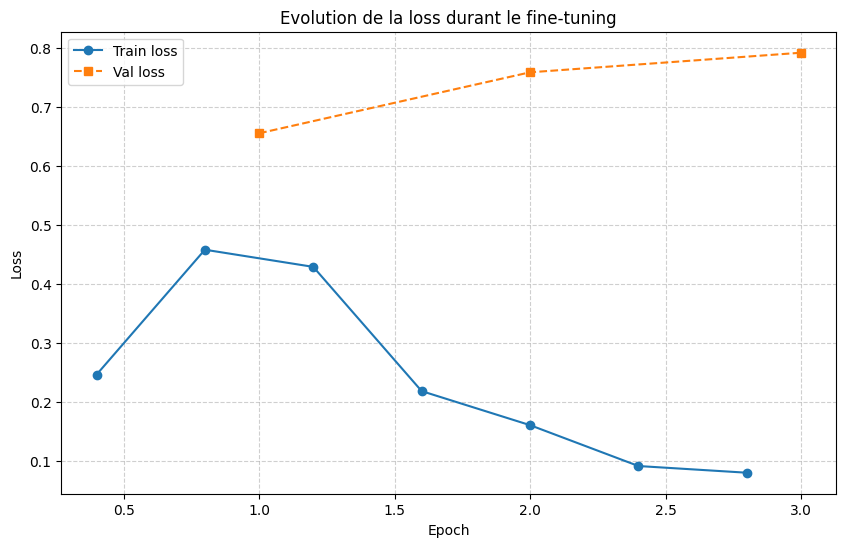

In [ ]:
# Extraire l'historique des logs du trainer
log_history = trainer.state.log_history

# Organiser les logs dans un DataFrame
df_logs = pd.DataFrame(log_history)

# Séparer les métriques d'entraînement et d'évaluation
df_train = df_logs[df_logs["loss"].notna()][["epoch", "loss", "step"]]
df_eval = df_logs[df_logs["eval_loss"].notna()][["epoch", "eval_loss", "step"]]

# Tracer les courbes de Loss
plt.figure(figsize=(10, 6))
plt.plot(df_train["epoch"], df_train["loss"], label="Train loss", marker='o')
if not df_eval.empty:
    plt.plot(df_eval["epoch"], df_eval["eval_loss"], label="Val loss", marker='s', linestyle='--')

plt.title("Evolution de la loss durant le fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [ ]:
# Sauvegarder l'adaptateur LoRA final sur Google Drive
output_adapter_path = CORPUS_DIR / "qwen_siemens_lora_adapter"

model_lora.save_pretrained(output_adapter_path)
tokenizer.save_pretrained(output_adapter_path)
print(f"Adaptateur enregistré avec succès dans {output_adapter_path} !")

Adaptateur enregistré avec succès dans /content/drive/MyDrive/Colab Notebooks/siemdiag/qwen_siemens_lora_adapter !


# 6. Evaluation Baseline vs Modèle fine-tuné

* pertinence et correction de la réponse ;
* respect du rôle et du format attendu ;
* prise en compte de l’historique ;
* capacité à reconnaître une demande hors périmètre ;
* présence d’informations inventées ou non vérifiables.

In [ ]:
from peft import PeftModel

# Chemin de l'adaptateur sauvegardé
output_adapter_path = CORPUS_DIR / "qwen_siemens_lora_adapter"

# Pour éviter de charger plusieurs fois l'adaptateur sur un modèle déjà modifié,
# on décharge l'adaptateur existant si 'model_lora' ou un adaptateur est déjà présent
if 'model_lora' in locals() or 'model_lora' in globals():
    try:
        print("Désactivation/Nettoyage de l'adaptateur précédent")
        del model_lora
        import gc
        import torch
        gc.collect()
        torch.cuda.empty_cache()
    except Exception:
        pass

print("Chargement de l'adaptateur LoRA...")
model_lora = PeftModel.from_pretrained(model, output_adapter_path)
model_lora.eval()
model_lora.config.use_cache = True  # désactivé par le gradient checkpointing de l'entraînement : génération très lente sinon
print("Modèle LoRA chargé.")

Chargement de l'adaptateur LoRA...


/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Modèle LoRA chargé.


## Évaluation sur `test.jsonl` : baseline vs LoRA vs réponse attendue

Les 20 questions de `test.jsonl` (15 du corpus, 5 hors périmètre) passent par le pipeline RAG complet. Pour comparer les deux modèles à contexte égal, la recherche est faite une seule fois par question (traduction anglaise par le modèle de base), puis chaque modèle génère sa réponse **sur les mêmes passages**.

Colonnes du tableau :
- **Passages attendus** : références (manuel, édition, pages) des sources citées dans la réponse attendue.
- **Passages récupérés** : les références réellement transmises par `siemens_index`, marquées "True" si elles font partie des passages attendus. **Bon passage récupéré** vaut "True" si au moins un passage attendu est récupéré. Attention : la comparaison se fait sur la référence de page, pas sur l'identifiant du passage. Si le retriever trouve la même information ailleurs (autre manuel, version FR/EN), la ligne sera marquée « manqué » à tort ; il faut le vérifier à l'œil.
- **Sources citées** : la réponse cite au moins un `[Source n]`, et chaque `n` renvoie à un passage réellement transmis. Sans objet (—) pour les questions hors périmètre.
- **Refus correct** : pour une question hors périmètre, la réponse est exactement `Information absente de la documentation fournie.` ; pour une question du corpus, la réponse ne contient pas de refus (pas de faux refus).

In [ ]:
# Jeu de test : questions, réponses attendues et références des passages attendus
test_set = load_jsonl(CORPUS_DIR / "test.jsonl")

def expected_refs(ex):
    """
    Références (manuel, édition, pages) des passages cités dans la réponse attendue.
    Liste vide pour une question hors périmètre.
    """
    refs = dict(re.findall(r"(?m)^\[Source (\d+)\] (.+?) \| ", ex["context"]))
    return sorted({refs[n] for n in re.findall(r"\[Source (\d+)\]", ex["response"])})

for ex in test_set:
    ex["hors"] = ex["response"] == REFUSAL
    ex["refs_attendues"] = expected_refs(ex)

print(f"{len(test_set)} questions, dont {sum(ex['hors'] for ex in test_set)} hors périmètre")

20 questions, dont 5 hors périmètre


In [ ]:
def sources_ok(answer, results):
    """
    Au moins une citation [Source n], et chacune renvoie à un passage réellement transmis.
    """
    ns = [int(n) for n in re.findall(r"Source (\d+)", answer)]
    return bool(ns) and all(1 <= n <= len(results) for n in ns)

def refus_ok(answer, hors):
    """
    Hors périmètre : refus au format exact attendu.
    Question du corpus : aucune formule de refus dans la réponse (pas de faux refus).
    """
    if hors:
        return answer.strip().strip("'\"«» ") == REFUSAL
    return _norm(REFUSAL) not in _norm(answer)

def generate_answer(agent, question, results, max_new_tokens=300):
    """
    Génération seule sur des passages déjà récupérés, comme dans rag_siemens (même contexte pour les deux modèles).
    """
    agent.reset_chat()
    ctx = format_context(results) or "(aucun extrait pertinent)"
    return agent.generate(question, context=ctx, max_new_tokens=max_new_tokens, temp=0)

In [ ]:
agent.set_system_prompt(SYSTEM_PROMPT_SIEMENS)
agent.reset_examples_few_shot()
agent.model = model_lora

rows = []
for i, ex in enumerate(test_set, 1):
    q = ex["question"]
    print(f"{i}/{len(test_set)} : {q}")

    with model_lora.disable_adapter():  # modèle de base : recherche (traduction) + réponse baseline
        agent.reset_chat()
        results = siemens_index.search(q, extra_queries=[translate_en(agent, q)])
        ans_base = generate_answer(agent, q, results)
    ans_lora = generate_answer(agent, q, results)  # adaptateur LoRA actif, mêmes passages

    refs = [c["ref"] for _, c in results]
    row = {
        "Question": q,
        "Hors périmètre": ex["hors"],
        "Réponse attendue": ex["response"],
        "Passages attendus": "\n".join(ex["refs_attendues"]) or "—",
        "Passages récupérés": "\n".join(f"{'True ' if r in ex['refs_attendues'] else ''}[Source {n}] {r}"
                                        for n, r in enumerate(refs, 1)) or "—",
        "Bon passage récupéré": None if ex["hors"] else any(r in ex["refs_attendues"] for r in refs),
    }
    for name, ans in [("Baseline", ans_base), ("LoRA", ans_lora)]:
        row[f"Réponse {name}"] = ans
        row[f"Sources citées ({name})"] = None if ex["hors"] else sources_ok(ans, results)
        row[f"Refus correct ({name})"] = refus_ok(ans, ex["hors"])
    rows.append(row)

res_test = pd.DataFrame(rows)

1/20 : Je laisse p0308 à 0, c'est grave ?
2/20 : Who won the last FIFA World Cup?
3/20 : C'est quoi MRP interconnection ?
4/20 : J'ai A50020 "Second controller missing" sur mon variateur en PROFINET.
5/20 : Comment savoir si le mode économie d'énergie PROFIenergy est actif ?
6/20 : Comment mettre en service un SINAMICS S120 avec un Smart Line Module ?
7/20 : Comment acquitter un F01600 STOP A ?
8/20 : Peut-on modifier le mappage des variables HART en RUN ?
9/20 : Alarme A07910 surchauffe moteur, quelles vérifications ?
10/20 : Je modifie le mapping PDO en CANopen et j'ai les alarmes A08756 puis A08757.
11/20 : Comment programmer un LOGO! 8 avec LOGO!Soft Comfort ?
12/20 : Mes traces sur le variateur sont refusées avec A02058 ou A02059, quel cycle choisir ?
13/20 : Que faire face à l'alarme A01900 en PROFIBUS ?
14/20 : Si j'acquitte une alarme d'un groupe d'alarmes, que deviennent les autres ?
15/20 : À quelles couches le firewall du module de sécurité peut-il filtrer ?
16/20 : Après tr

In [ ]:
 # Tableau comparatif : booléens affichés en True / False (— : sans objet)
bool_cols = ["Hors périmètre", "Bon passage récupéré",
             "Sources citées (Baseline)", "Refus correct (Baseline)",
             "Sources citées (LoRA)", "Refus correct (LoRA)"]
fmt_bool = lambda v: "—" if v is None or pd.isna(v) else ("True" if v else "False")

cols = ["Question", "Hors périmètre", "Réponse attendue", "Passages attendus", "Passages récupérés", "Bon passage récupéré",
        "Réponse Baseline", "Sources citées (Baseline)", "Refus correct (Baseline)",
        "Réponse LoRA", "Sources citées (LoRA)", "Refus correct (LoRA)"]
display(res_test[cols].assign(**{c: res_test[c].map(fmt_bool) for c in bool_cols}).style
        .set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top", "font-size": "12px"}))

,Question,Hors périmètre,Réponse attendue,Passages attendus,Passages récupérés,Bon passage récupéré,Réponse Baseline,Sources citées (Baseline),Refus correct (Baseline),Réponse LoRA,Sources citées (LoRA),Refus correct (LoRA)
0,"Je laisse p0308 à 0, c'est grave ?",False,"Non : avec p0308 = 0,000, le facteur de puissance est calculé en interne [Source 2]. Le paramètre n'est pas utilisé pour les moteurs synchrones et il est prérempli et protégé en écriture si un moteur catalogue est choisi (p0301) [Source 2].","List Manual G120C, éd. 09/2020, p.62-63","True [Source 1] List Manual G120C, éd. 09/2020, p.62-63 [Source 2] List Manual G120C, éd. 09/2020, p.51 [Source 3] Module AI 8xHART HF, éd. 05/2023 (A5E51346446-AA), p.87 [Source 4] Module AI 8xHART HF, éd. 05/2023 (A5E51346446-AA), p.88 [Source 5] Manuel de fonction Communication, éd. 11/2025 (A5E03735816-AN), p.213-214",True,"Si vous laissez p0308 à 0, cela signifie que vous ne définissez pas de puissance facteur de moteur (power factor) pour votre moteur. Cependant, cela n'est pas nécessairement ""grave"" car cette valeur est par défaut calculée internement par le système. Cependant, si vous avez besoin de contrôler explicitement le facteur de puissance, il serait préférable de définir une valeur. Vérifiez toujours la documentation de votre système pour comprendre les conséquences potentielles de cette configuration. [Source 1]",True,True,Non : p0308 = 0 provoque une calculisation de la puissance facteur (cos φ) ; p0308 doit être paramétré dès p0100 = 0 [Source 1].,True,True
1,Who won the last FIFA World Cup?,True,Information absente de la documentation fournie.,—,"[Source 1] Manuel de fonction Web Server, éd. 11/2025 (A5E53797648-AB), p.131-132 [Source 2] List Manual G120C, éd. 09/2020, p.625 [Source 3] Manuel de fonction Web Server, éd. 11/2025 (A5E53797648-AB), p.105 [Source 4] Module AI 8xHART HF, éd. 05/2023 (A5E51346446-AA), p.74 [Source 5] System Diagnostics with S7-1500 and TIA Portal, éd. 09/2020, p.17",—,Information absente de la documentation fournie.,—,True,Information absente de la documentation fournie.,—,True
2,C'est quoi MRP interconnection ?,False,"Une extension de MRP qui permet le couplage redondant de deux anneaux MRP ou plus dans un réseau PROFINET, spécifiée dans la norme IEC 62439-2 (édition 3) [Source 2].","PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.176","True [Source 1] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.176 [Source 2] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.177 [Source 3] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.307-308 [Source 4] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.297-301 [Source 5] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.178-180",True,MRP interconnection est une fonctionnalité qui permet la couplage redondant de deux ou plusieurs réseaux MRP dans les réseaux PROFINET. Elle permet ainsi de surveiller des topologies plus grandes avec la redondance du réseau. Cette fonctionnalité est spécifiée dans le standard IEC 62439-2 (Édition 3). Elle permet de dépasser le nombre maximum de 50 dispositifs dans un réseau parmi un réseau redondant lors de la mise en œuvre de topologies réseau redondant.,False,True,"L'interconnexion MRP permet de raccorder de deux à plusieurs tours avec MRP en réseau PROFINET, c'est une amélioration de MRP [Source 1].",True,True
3,"J'ai A50020 ""Second controller missing"" sur mon variateur en PROFINET.",False,La fonction Shared Device est activée (p8929 = 2) mais une seule connexion à un contrôleur PROFINET est présente [Source 1]. Vérifiez la configuration des contrôleurs PROFINET et le réglage de p8929 [Source 1].,"List Manual G120C, éd. 09/2020, p.752","True [Source 1] List Manual G120C, éd. 09/2020, p.752 [Source 2] List Manual G120C, éd. 09/2020, p.479 [Source 3] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.144-145 [Source 4] PROFINET with STEP 7 (V18), éd. 11/2022 (A5E03444486-AM), p.135-136

In [ ]:
# Synthèse par modèle
d_in, d_out = res_test[~res_test["Hors périmètre"]], res_test[res_test["Hors périmètre"]]
n_words = lambda s: round(s.str.split().str.len().mean(), 1)

summary = pd.DataFrame({
    name: {
        "Sources citées (questions du corpus)": f"{d_in[f'Sources citées ({name})'].astype(bool).sum()}/{len(d_in)}",
        "Refus correct (hors périmètre, format exact)": f"{d_out[f'Refus correct ({name})'].sum()}/{len(d_out)}",
        "Faux refus (questions du corpus)": f"{(~d_in[f'Refus correct ({name})'].astype(bool)).sum()}/{len(d_in)}",
        "Longueur moyenne des réponses (mots)": n_words(res_test[f"Réponse {name}"]),
    } for name in ["Baseline", "LoRA"]})
summary["Attendu"] = ["—", "—", "—", n_words(res_test["Réponse attendue"])]

print(f"Bon passage récupéré : {d_in['Bon passage récupéré'].astype(bool).sum()}/{len(d_in)} questions du corpus")
display(summary)

Bon passage récupéré : 13/15 questions du corpus


,Baseline,LoRA,Attendu
Sources citées (questions du corpus),6/15,15/15,—
"Refus correct (hors périmètre, format exact)",1/5,3/5,—
Faux refus (questions du corpus),0/15,0/15,—
Longueur moyenne des réponses (mots),79.8,26.9,24.6


# 7. Interface Gradio

In [ ]:
from pathlib import Path
from peft import PeftModel

try: # sur Colab, les fichiers du corpus sont sur le Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
CORPUS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/siemdiag")
if not CORPUS_DIR.exists():  # sinon, exécution locale
    CORPUS_DIR = Path("ressources")

In [ ]:
# Chemin de l'adaptateur sauvegardé
output_adapter_path = CORPUS_DIR / "qwen_siemens_lora_adapter"

# Pour éviter de charger plusieurs fois l'adaptateur sur un modèle déjà modifié,
# on décharge l'adaptateur existant si 'model_lora' ou un adaptateur est déjà présent
if 'model_lora' in locals() or 'model_lora' in globals():
    try:
        print("Désactivation/Nettoyage de l'adaptateur précédent")
        del model_lora
        import gc
        import torch
        gc.collect()
        torch.cuda.empty_cache()
    except Exception:
        pass

print("Chargement de l'adaptateur LoRA...")
model_lora = PeftModel.from_pretrained(model, output_adapter_path)
model_lora.eval()
model_lora.config.use_cache = True  # désactivé par le gradient checkpointing de l'entraînement : génération très lente sinon
print("Modèle LoRA chargé.")

Désactivation/Nettoyage de l'adaptateur précédent
Chargement de l'adaptateur LoRA...
Modèle LoRA chargé.


In [ ]:
!pip install gradio

### Interface utilisateur Gradio pour l'assistant SiemDiag

Cette interface permet aux techniciens d'échanger en direct avec l'assistant. Elle contient :
- L'historique des échanges
- Une zone de saisie pour vos questions
- Un bouton pour effacer l'historique et recommencer la session
- Un rappel des fonctions et limites de l'agent.


In [ ]:
agent.set_system_prompt(SYSTEM_PROMPT_SIEMENS)
agent.reset_examples_few_shot()
agent.model = model_lora

In [ ]:
import gradio as gr
import re

def respond(message, chat_history):
    if not message.strip():
        return "", chat_history

    # Appeler la pipeline de rag siemens avec la question
    answer, results = rag_siemens(agent, siemens_index, message)

    # ajouter à l'historique du chat
    chat_history = chat_history + [{"role": "user", "content": message},
                                   {"role": "assistant", "content": answer}]

    # extraire les images références avec du regex
    path_imgs = re.findall(r"\b\w+\.png\b", answer)

    # Ajout de l'image dans le chat Gradio si elle est trouvée
    for img in path_imgs:
        # Construct full path to image file inside CORPUS_DIR/figures/
        subfolder = img.split("_")[0] # e.g. 'd18' from 'd18_p0378_f1.png'
        full_path = CORPUS_DIR / "figures" / subfolder / img
        if full_path.exists():
            chat_history.append({
                "role": "assistant",
                "content": {"path": str(full_path), "mime_type": "image/png"}
            })

    return "", chat_history

def clear_history():
    agent.reset_chat()
    return []

# Construction de l'interface Gradio
with gr.Blocks(title="SiemDiag Assistant") as demo:
    gr.Markdown("""# Assistant Documentaire SiemDiag
**Rôle :** Je suis votre assistant de maintenance industrielle spécialisé sur les automates Siemens **S7-1500** et variateurs **SINAMICS G120C**.

**Limites :**
- Je réponds uniquement à partir de la documentation officielle Siemens fournie.
- Si l'information demandée n'est pas présente dans mes extraits de documentation, je répondrai : *'Information absente de la documentation fournie.'*
- Je ne peux pas traiter de questions de culture générale ou hors de mon périmètre industriel.
""")

    chatbot = gr.Chatbot(label="Conversation SiemDiag")
    msg = gr.Textbox(label="Posez votre question technique", placeholder="Saisissez votre message ici...")

    with gr.Row():
        submit_btn = gr.Button("Envoyer", variant="primary")
        clear_btn = gr.Button("Réinitialiser l'historique")

    # Liaison des actions
    msg.submit(respond, inputs=[msg, chatbot], outputs=[msg, chatbot])
    submit_btn.click(respond, inputs=[msg, chatbot], outputs=[msg, chatbot])
    clear_btn.click(clear_history, outputs=[chatbot])

# Lancement de l'application
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f29c3701065a54ca50.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
